# 💳 Credit Card Fraud Detection — Exploratory Data Analysis

**Dataset:** Credit Card Fraud Detection (Kaggle — ULB Machine Learning Group)  
**Target:** `Class` — 0 = Legitimate Transaction, 1 = Fraudulent Transaction  
**Author:** Narendra Kalam

---

## 🏦 Business Problem

Credit card fraud causes billions of dollars in losses annually worldwide. Banks must detect fraudulent transactions in **real-time** — often within milliseconds — while minimizing false alarms that frustrate genuine customers.

**Key challenges:**
- Transactions are extremely imbalanced (fraud < 0.2% of all transactions)
- Standard accuracy is misleading — a model predicting "Legit" for everything gets 99.8% accuracy but catches zero fraud
- Features V1–V28 are PCA-transformed for confidentiality — no domain labels available
- The cost of missing fraud (False Negative) is far higher than incorrectly flagging a legit transaction (False Positive)

**Goal:** Build a system that maximises **recall** (catching real fraud) while maintaining acceptable **precision** (not overwhelming analysts with false alerts) — and deploy it as a real-time decision engine with APPROVE / REVIEW / BLOCK outputs.

---

## 📌 Notebook Workflow

| Step | Topic |
|------|-------|
| 1 | Import libraries |
| 2 | Data loading and initial inspection |
| 3 | Dataset structure and data types |
| 4 | Missing values analysis |
| 5 | Duplicate detection and cleaning |
| 6 | Statistical summary heatmap |
| 7 | Class imbalance analysis |
| 8 | Transaction amount analysis |
| 9 | Transaction time analysis |
| 10 | Fraud rate by hour of day |
| 11 | Fraud rate by day |
| 12 | Amount distribution — Fraud vs Legitimate |
| 13 | Log-amount transformation |
| 14 | PCA feature distributions (V1–V28) |
| 15 | Top PCA features — fraud signal strength |
| 16 | Bivariate analysis — PCA features vs target |
| 17 | Feature correlation matrix |
| 18 | Outlier analysis by class |
| 19 | Fraud rate by amount bucket |
| 20 | Feature engineering preview |
| 21 | Graph risk score analysis |
| 22 | Anomaly score distribution |
| 23 | Class imbalance — SMOTE preview |
| 24 | Feature scaling preview |
| 25 | Key insights summary |

---


---
## Step 1 — Import Libraries
---
**Why:** All required libraries imported upfront with explicit version printing.  
`scipy.stats` enables hypothesis testing (Mann-Whitney U) to statistically confirm visual patterns.  
`networkx` powers the graph-based fraud ring detection feature used in the production pipeline.  

**Business insight:** In a payments environment the same libraries and versions must run in training, batch scoring and the real-time API. A pinned, reproducible import block is the first step toward train/serve parity and an auditable model-risk file.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import networkx as nx

from scipy import stats
from sklearn.preprocessing    import StandardScaler, PowerTransformer
from sklearn.model_selection  import train_test_split
from sklearn.ensemble         import IsolationForest
from imblearn.over_sampling   import SMOTE

# ── Plot style ────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.dpi":       120,
    "figure.figsize":   (12, 5),
    "axes.titlesize":   13,
    "axes.titleweight": "bold",
    "axes.labelsize":   11,
    "axes.spines.top":  False,
    "axes.spines.right":False,
})

FRAUD_COLOR  = "#E74C3C"   # red   — fraud / high-risk
LEGIT_COLOR  = "#2ECC71"   # green — legitimate / low-risk
ACCENT_COLOR = "#3498DB"   # blue  — neutral / highlight
WARN_COLOR   = "#F39C12"   # amber — borderline / review

print("✅ All libraries imported successfully")
print(f"   NumPy      : {np.__version__}")
print(f"   Pandas     : {pd.__version__}")
print(f"   NetworkX   : {nx.__version__}")

✅ All libraries imported successfully
   NumPy      : 1.26.4
   Pandas     : 2.2.2
   NetworkX   : 3.4.2


📌 **Observation:**

- All libraries import cleanly and the version printout confirms the environment. `networkx` (graph features, Step 21), `imblearn` (SMOTE, Step 23) and `scipy.stats` (Mann-Whitney U, Q-Q plots) are all used later in the notebook.

💡 **Pipeline decision:** The same library set is pinned in `requirements.txt` for the training pipeline, the FastAPI service and the Streamlit dashboard, so the environment used for this EDA is the environment used in production.

---
## Step 2 — Data Loading and Initial Inspection
---
**Why:** First look at raw data — shape, column names, and a transposed `head()` for easy reading when many columns exist.  

**Business context:** The dataset contains 284,807 credit card transactions made by European cardholders over two days in September 2013. Features V1–V28 are principal components obtained via PCA — the original features cannot be disclosed due to confidentiality. Only `Time` and `Amount` are original features. `Class` is the target: 1 = fraud, 0 = legitimate.


In [2]:
# ── Update path to your local dataset ────────────────────────
DATA_PATH = "D:\\Data Science Datasets\\Credit Card Fraud Detection.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully")
print(f"Shape : {df.shape[0]:,} rows × {df.shape[1]} columns")
print()
print("First 3 rows (transposed for readability):")
df.head(3).T

Dataset loaded successfully
Shape : 284,807 rows × 31 columns

First 3 rows (transposed for readability):


,0,1,2
Time,0.000000,0.000000,1.000000
V1,-1.359807,1.191857,-1.358354
V2,-0.072781,0.266151,-1.340163
V3,2.536347,0.166480,1.773209
V4,1.378155,0.448154,0.379780
V5,-0.338321,0.060018,-0.503198
V6,0.462388,-0.082361,1.800499
V7,0.239599,-0.078803,0.791461
V8,0.098698,0.085102,0.247676
V9,0.363787,-0.255425,-1.514654


📌 **Observation:**

- The file has **284,807 rows × 31 columns**: `Time`, `V1`–`V28`, `Amount` and the target `Class`. Everything is numeric with no formatting problems.
- `V1`–`V28` are already on a PCA scale (values around ±1–5), while `Amount` is in raw dollars (e.g. 149.62, 378.66) — the two groups live on very different scales.

💡 **Pipeline decision:** `validate_input_data()` checks for the required columns `['Time', 'Amount', 'Class']` before any processing begins — fast-failing on malformed inputs. The different scales motivate the dual-preprocessor design in Step 24.

---
## Step 3 — Dataset Structure and Data Types
---
**Why:** Understanding dtypes is critical before any transformation. All features should be float64. Any object or int columns need special handling.  

**Business insight:** PCA components (V1–V28) are zero-mean by construction — this means they need only scaling, not centering. `Amount` and `Time` are the only features we can engineer directly since they haven't been PCA-transformed.


In [3]:
info_df = pd.DataFrame({
    "dtype":    df.dtypes,
    "nunique":  df.nunique(),
    "nulls":    df.isnull().sum(),
    "null_%":   (df.isnull().mean() * 100).round(4),
    "min":      df.min().round(4),
    "max":      df.max().round(4),
    "mean":     df.mean().round(4),
})

print(info_df.to_string())

          dtype  nunique  nulls  null_%       min          max        mean
Time    float64   124592      0     0.0    0.0000  172792.0000  94813.8596
V1      float64   275663      0     0.0  -56.4075       2.4549      0.0000
V2      float64   275663      0     0.0  -72.7157      22.0577      0.0000
V3      float64   275663      0     0.0  -48.3256       9.3826     -0.0000
V4      float64   275663      0     0.0   -5.6832      16.8753      0.0000
V5      float64   275663      0     0.0 -113.7433      34.8017      0.0000
V6      float64   275663      0     0.0  -26.1605      73.3016      0.0000
V7      float64   275663      0     0.0  -43.5572     120.5895     -0.0000
V8      float64   275663      0     0.0  -73.2167      20.0072      0.0000
V9      float64   275663      0     0.0  -13.4341      15.5950     -0.0000
V10     float64   275663      0     0.0  -24.5883      23.7451      0.0000
V11     float64   275663      0     0.0   -4.7975      12.0189      0.0000
V12     float64   275663 

📌 **Observation:**

- All 31 columns are `float64` except `Class` (`int64`, exactly 2 unique values; mean 0.0017 → 0.17% fraud before de-duplication). No object or categorical columns.
- `V1`–`V28` have means of 0.0000 (PCA construction) but very different ranges and heavy tails (e.g. `V5` from −113.7 to +34.8, `V7` up to +120.6).
- `Amount` spans $0 – $25,691.16 (mean $88.35); `Time` spans 0 – 172,792 seconds.

💡 **Pipeline decision:** No categorical encoding is needed, so plain `SMOTE` is sufficient (no `SMOTENC`). The heavy tails of the PCA features are handled by the IQR `Clipper` (Step 18); `Amount` and `Time` are the only raw-scale columns and are engineered in Steps 9 and 13.

---
## Step 4 — Missing Values Analysis
---
**Why:** Missing values must be explicitly identified before modeling. Even one missing value in a PCA feature can cascade through the entire pipeline and cause silent failures.  

**Business insight:** In live transaction data, missing values can occur when upstream systems fail to transmit all fields. Our pipeline must handle this gracefully — rejecting or imputing as appropriate.


Total missing values across all columns: 0

✅ No missing values — dataset is complete


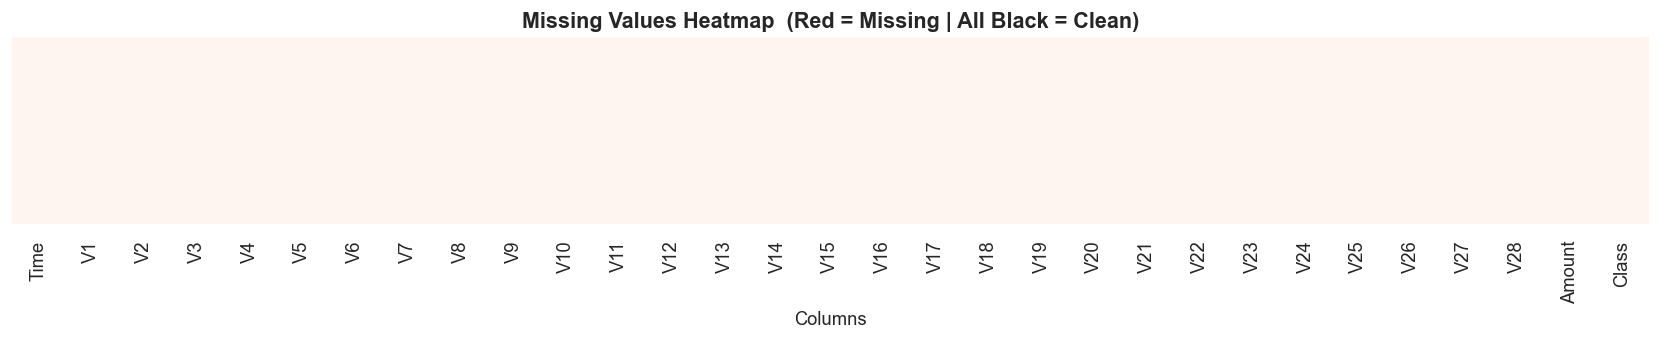

In [4]:
total_nulls = df.isnull().sum().sum()
print(f"Total missing values across all columns: {total_nulls}")
print()

if total_nulls == 0:
    print("✅ No missing values — dataset is complete")
else:
    missing = df.isnull().sum()
    print("Columns with missing values:")
    print(missing[missing > 0].to_string())

# Visual confirmation
fig, ax = plt.subplots(figsize=(14, 3))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False,
            cmap="Reds", ax=ax)
ax.set_title("Missing Values Heatmap  (Red = Missing | All Black = Clean)")
ax.set_xlabel("Columns")
plt.tight_layout()
plt.show()

📌 **Observation:**

- **Zero missing values** across all 31 columns: the missing-value heatmap is one uniform pale strip with no highlighted cell (the plot title says "All Black = Clean", but a clean frame renders as an even pale background).

💡 **Pipeline decision:** No imputation step is needed for training. `validate_input_data()` still runs a null check at inference time — a live transaction stream can drop fields that this clean batch never did, and such records should be rejected or routed to REVIEW rather than silently scored.

---
## Step 5 — Duplicate Detection and Cleaning
---
**Why:** Duplicate rows can cause data leakage — the same transaction appearing in both train and validation sets inflates CV scores. In fraud detection, duplicates could represent real repeated transactions OR data pipeline errors.  

**Business insight:** In payment systems, duplicate transactions are themselves a fraud signal (replay attacks). However, exact row duplicates in a flat CSV more likely indicate a pipeline error than genuine replay fraud.


In [5]:
dupes = df.duplicated().sum()
print(f"Duplicate rows found: {dupes:,}")

if dupes > 0:
    # Check if duplicates are fraud or legit
    dupe_mask    = df.duplicated(keep=False)
    dupe_classes = df[dupe_mask]["Class"].value_counts()
    print(f"\nClass breakdown of duplicate rows:")
    print(dupe_classes.to_string())
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"\n✅ Duplicates removed. New shape: {df.shape}")
else:
    print("✅ No duplicates found — dataset is clean")

Duplicate rows found: 1,081

Class breakdown of duplicate rows:
Class
0    1822
1      32

✅ Duplicates removed. New shape: (283726, 31)


📌 **Observation:**

- **1,081 exact duplicate rows** (0.38% of the file) are found; the duplicated groups contain 1,822 legitimate and 32 fraud rows.
- After `drop_duplicates()` the dataset shrinks from 284,807 to **283,726 rows**, and the fraud count falls from **492 to 473** — 19 of the already scarce positives are removed.

💡 **Pipeline decision:** `drop_duplicates()` runs inside `validate_input_data()` **before** `train_test_split`, so no identical row can land in both train and test. All class statistics from here on (0.167% fraud, 598 : 1) are computed on the **de-duplicated** data.

---
## Step 6 — Statistical Summary Heatmap
---
**Why:** Descriptive statistics across 31 features with very different scales are hard to compare in table form. A normalised heatmap instantly shows which features have the widest spread or the most extreme maxima.  

**Business insight:** Only `Time` and `Amount` are on raw business scales, so they are the columns where spread and extremes are directly interpretable. The coefficient of variation (std/mean) is only meaningful for features with a non-zero mean — for zero-mean PCA components it explodes and carries no information about fraud signal.

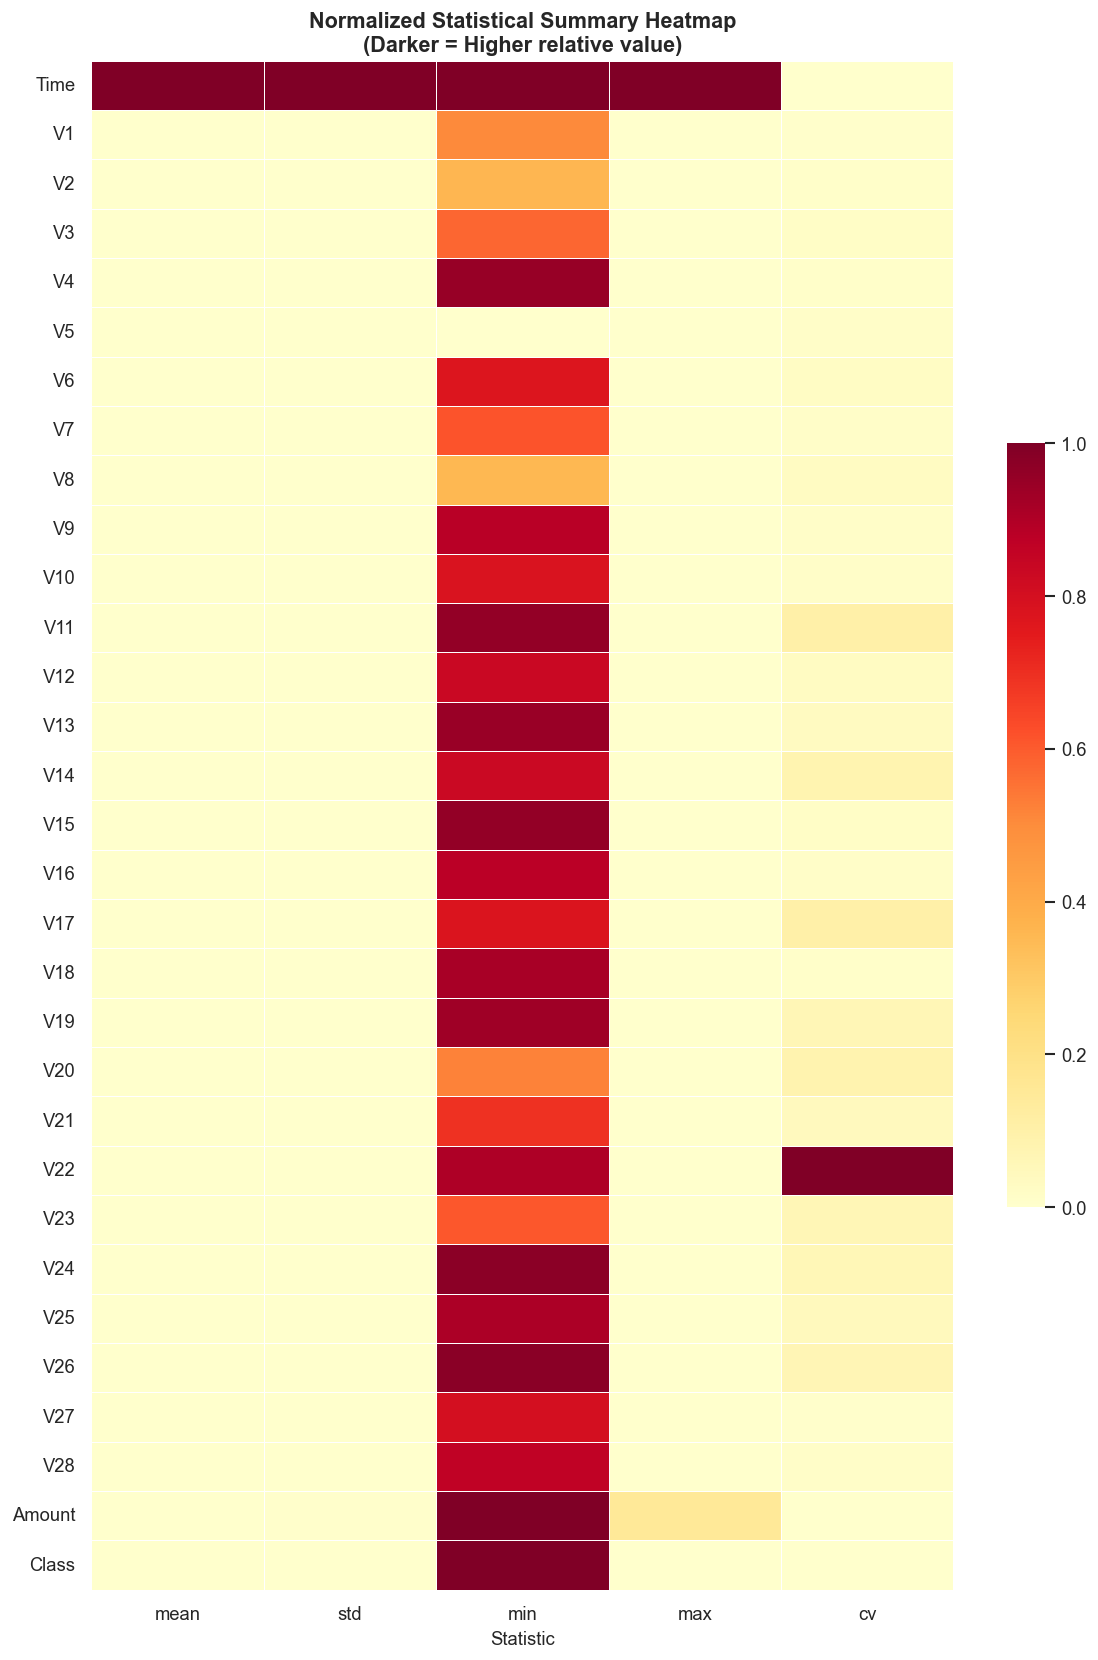

Top 5 features by Coefficient of Variation (most variable):
V22    48214.7676
V11     5049.2271
V17     4951.2379
V20     4113.7076
V14     3773.8795


In [6]:
desc = df.describe().T
desc["cv"] = (desc["std"] / desc["mean"].replace(0, 1)).abs()

# Normalize per column for heatmap
from sklearn.preprocessing import MinMaxScaler
norm = MinMaxScaler()
desc_norm = pd.DataFrame(
    norm.fit_transform(desc[["mean","std","min","max","cv"]]),
    index=desc.index,
    columns=["mean","std","min","max","cv"]
)

fig, ax = plt.subplots(figsize=(10, 14))
sns.heatmap(desc_norm, annot=False, cmap="YlOrRd",
            linewidths=0.3, ax=ax, cbar_kws={"shrink": 0.5})
ax.set_title("Normalized Statistical Summary Heatmap\n(Darker = Higher relative value)")
ax.set_xlabel("Statistic")
plt.tight_layout()
plt.show()

print("Top 5 features by Coefficient of Variation (most variable):")
print(desc["cv"].sort_values(ascending=False).head(5).round(4).to_string())

📌 **Observation:**

- `Time` (raw seconds, max 172,792) is the darkest cell in the `mean`, `std` and `max` columns; `Amount` is a distant second in `max` ($25,691) and `std` (≈ $250). Every `V` feature is a pale cell in those columns.
- The `min` column is darkest for `Time`, `Amount` and `Class` (minimum 0) and palest for features with extreme negative minima — `V5` (−113.7), `V1`, `V2`, `V8`, `V20` — which marks the heavy negative tails of the PCA components.
- In the `cv` column **`V22` is the single darkest cell (CV ≈ 48,000)**, followed by `V11`, `V17`, `V20` and `V14` (thousands), purely because their means are ≈ 0. This ranking is **an artefact, not a signal**; `Amount` and `Time` do not appear in it.

💡 **Pipeline decision:** The coefficient of variation is **not** used for feature selection. `Time` is replaced by engineered `hour` / `day` features and `Amount` is `log1p`-transformed in `load_and_engineer()`; the PCA features go directly into the Clipper → StandardScaler chain, which also addresses the heavy negative tails seen in the `min` column.

---
## Step 7 — Class Imbalance Analysis
---
**Why:** This is the most critical insight for the entire model design. A naive model predicting "Legitimate" for every transaction achieves 99.8%+ accuracy but catches **zero fraud** — completely useless for the business.  

**Business insight:** Fraud is rare by design — fraudsters avoid detection by keeping volume low. The 598:1 imbalance ratio means traditional accuracy is deceptive. This drives our choice of **PR-AUC** and **F1-score** as primary metrics, and motivates SMOTE for training.


Legitimate transactions     :  283,253  (99.8333%)
Fraudulent transactions     :      473  (0.1667%)
Imbalance ratio             : 598:1

Dummy model accuracy (predict all Legit): 99.83%  ← misleading!
Dummy model recall on fraud             :   0.00%  ← zero fraud caught


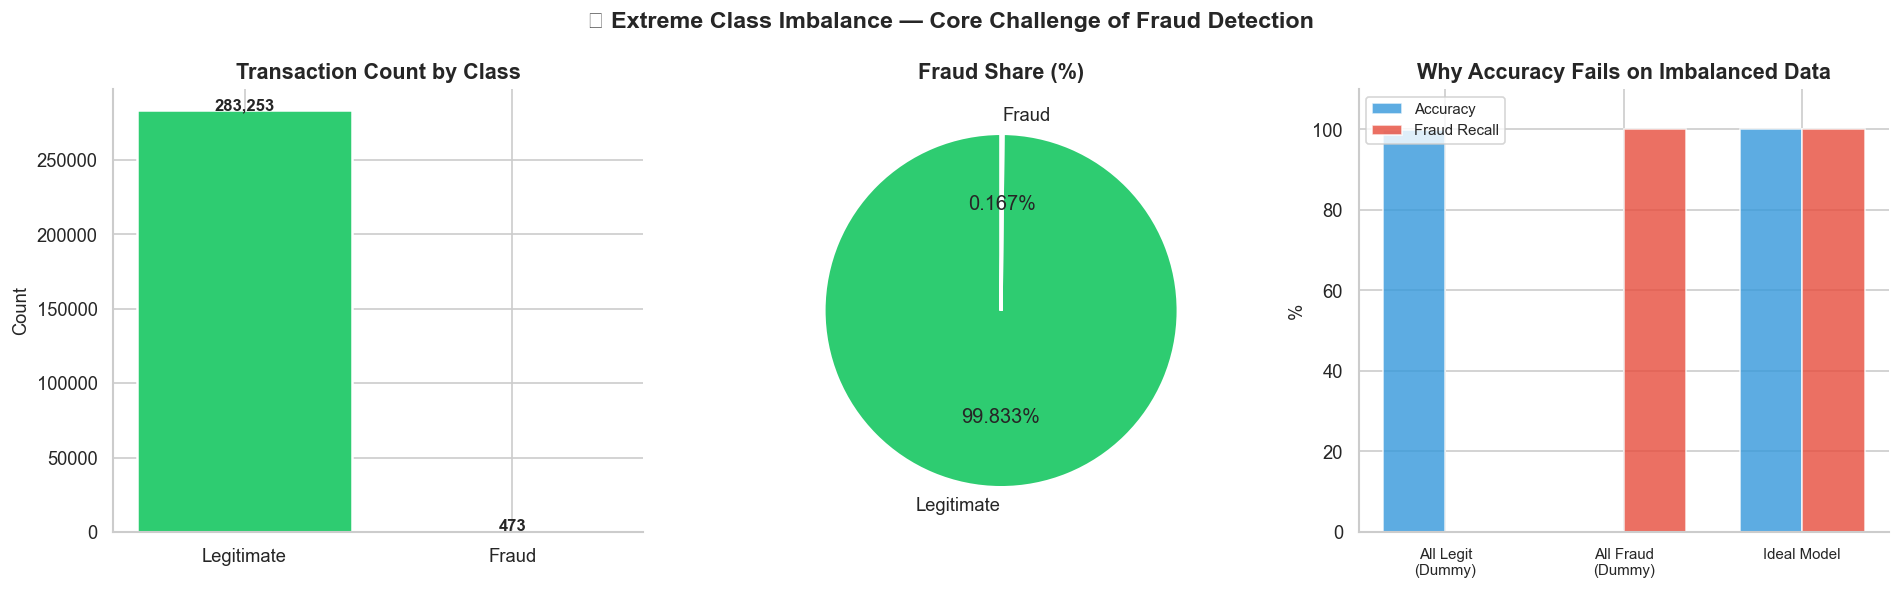

In [7]:
counts     = df["Class"].value_counts()
fraud_rate = df["Class"].mean() * 100

legit_n = counts[0]
fraud_n = counts[1]
ratio   = legit_n // fraud_n

print(f"{'Legitimate transactions':<28}: {legit_n:>8,}  ({100-fraud_rate:.4f}%)")
print(f"{'Fraudulent transactions':<28}: {fraud_n:>8,}  ({fraud_rate:.4f}%)")
print(f"{'Imbalance ratio':<28}: {ratio}:1")
print()

# Dummy model accuracy
dummy_acc = legit_n / (legit_n + fraud_n) * 100
print(f"Dummy model accuracy (predict all Legit): {dummy_acc:.2f}%  ← misleading!")
print(f"Dummy model recall on fraud             :   0.00%  ← zero fraud caught")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Bar chart
axes[0].bar(["Legitimate", "Fraud"], [legit_n, fraud_n],
            color=[LEGIT_COLOR, FRAUD_COLOR], edgecolor="white", linewidth=1.5)
axes[0].set_title("Transaction Count by Class")
axes[0].set_ylabel("Count")
for i, v in enumerate([legit_n, fraud_n]):
    axes[0].text(i, v + 500, f"{v:,}", ha="center", fontweight="bold", fontsize=10)

# Pie chart
axes[1].pie([legit_n, fraud_n],
            labels=["Legitimate", "Fraud"],
            colors=[LEGIT_COLOR, FRAUD_COLOR],
            autopct="%1.3f%%", startangle=90,
            wedgeprops={"edgecolor":"white","linewidth":2})
axes[1].set_title("Fraud Share (%)")

# Why accuracy fails
categories = ["All Legit\n(Dummy)", "All Fraud\n(Dummy)", "Ideal Model"]
accuracy   = [dummy_acc, fraud_rate, 100]
recall_fr  = [0, 100, 100]
x = np.arange(3)
w = 0.35
axes[2].bar(x - w/2, accuracy,  w, label="Accuracy",      color=ACCENT_COLOR, alpha=0.8)
axes[2].bar(x + w/2, recall_fr, w, label="Fraud Recall",  color=FRAUD_COLOR,  alpha=0.8)
axes[2].set_xticks(x)
axes[2].set_xticklabels(categories, fontsize=9)
axes[2].set_ylim(0, 110)
axes[2].set_ylabel("%")
axes[2].set_title("Why Accuracy Fails on Imbalanced Data")
axes[2].legend(fontsize=9)

plt.suptitle("🚨 Extreme Class Imbalance — Core Challenge of Fraud Detection",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

📌 **Observation:**

- Only **473 of 283,726 transactions (0.167%) are fraudulent** — an imbalance of **598 : 1** after de-duplication (599 : 1 inside the 80% training split: 226,602 legitimate vs 378 fraud).
- The dummy "everything is legitimate" model reaches **99.83% accuracy with 0% fraud recall**, confirming that accuracy is meaningless here.

💡 **Pipeline decision:** SMOTE is applied on the **training set only** (Step 23). **PR-AUC** is the primary CV metric — ROC-AUC is also optimistic at this imbalance — and F1 is used for threshold tuning and model selection. `scale_pos_weight` is additionally set in XGBoost / LightGBM so imbalance is handled at the model level too.

---
## Step 8 — Transaction Amount Analysis
---
**Why:** `Amount` is one of only two interpretable features (alongside `Time`). Understanding its distribution directly informs the rule engine — e.g., "Block all transactions above $X". It also motivates the log transformation applied in the pipeline.  

**Business insight:** Fraudsters often test with small amounts first (card testing attacks), then make large purchases. But very large amounts are also suspicious because they represent high-value targets. Both tails of the distribution matter.


Transaction Amount Statistics (full dataset):
count    283726.0000
mean         88.4727
std         250.3994
min           0.0000
25%           5.6000
50%          22.0000
75%          77.5100
max       25691.1600

Skewness : 16.9788  (>1 = significantly right-skewed)
Kurtosis : 844.4713  (>3 = heavy tails)

Fraud avg amount   : $  123.87
Legit avg amount   : $   88.41
Fraud max amount   : $ 2125.87
Legit max amount   : $25691.16
Fraud median       : $    9.82


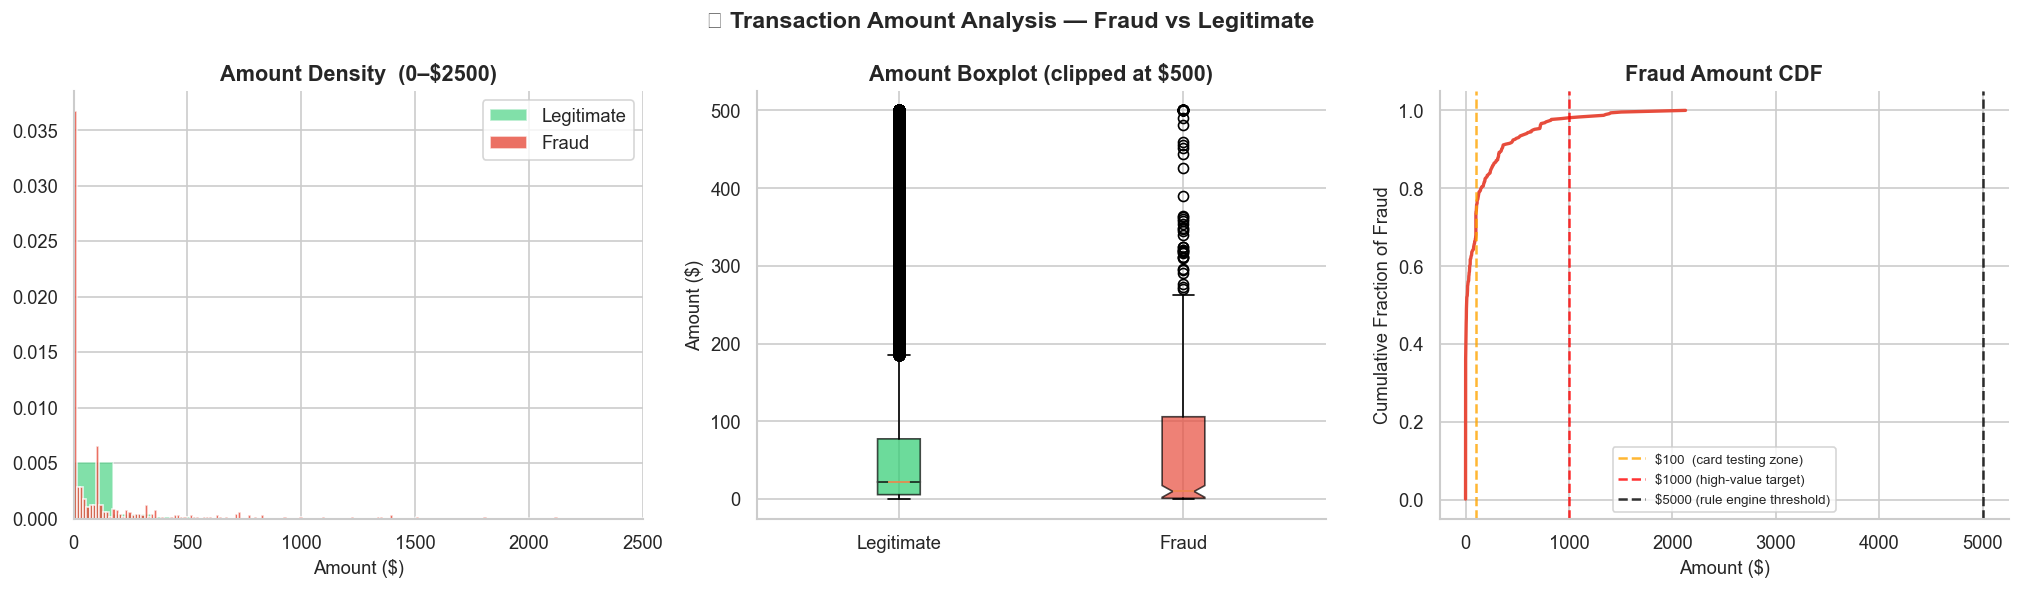

In [8]:
fraud_df = df[df["Class"] == 1]
legit_df = df[df["Class"] == 0]

print("Transaction Amount Statistics (full dataset):")
print(df["Amount"].describe().round(4).to_string())
print(f"\nSkewness : {df['Amount'].skew():.4f}  (>1 = significantly right-skewed)")
print(f"Kurtosis : {df['Amount'].kurtosis():.4f}  (>3 = heavy tails)")
print()
print(f"Fraud avg amount   : ${fraud_df['Amount'].mean():>8.2f}")
print(f"Legit avg amount   : ${legit_df['Amount'].mean():>8.2f}")
print(f"Fraud max amount   : ${fraud_df['Amount'].max():>8.2f}")
print(f"Legit max amount   : ${legit_df['Amount'].max():>8.2f}")
print(f"Fraud median       : ${fraud_df['Amount'].median():>8.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Full distribution (log scale y-axis to see fraud)
axes[0].hist(legit_df["Amount"], bins=150, alpha=0.6, color=LEGIT_COLOR,
             label="Legitimate", density=True)
axes[0].hist(fraud_df["Amount"], bins=150, alpha=0.8, color=FRAUD_COLOR,
             label="Fraud",      density=True)
axes[0].set_xlim(0, 2500)
axes[0].set_title("Amount Density  (0–$2500)")
axes[0].set_xlabel("Amount ($)")
axes[0].legend()

# Boxplot comparison
bp = axes[1].boxplot([legit_df["Amount"].clip(0, 500),
                       fraud_df["Amount"].clip(0, 500)],
                      labels=["Legitimate", "Fraud"],
                      patch_artist=True,
                      notch=True,
                      boxprops=dict(alpha=0.7))
bp["boxes"][0].set_facecolor(LEGIT_COLOR)
bp["boxes"][1].set_facecolor(FRAUD_COLOR)
axes[1].set_title("Amount Boxplot (clipped at $500)")
axes[1].set_ylabel("Amount ($)")

# CDF of fraud amounts
amounts_sorted = np.sort(fraud_df["Amount"])
cdf = np.arange(1, len(amounts_sorted)+1) / len(amounts_sorted)
axes[2].plot(amounts_sorted, cdf, color=FRAUD_COLOR, linewidth=2)
axes[2].axvline(100,  color="orange", linestyle="--", alpha=0.8, label="$100  (card testing zone)")
axes[2].axvline(1000, color="red",    linestyle="--", alpha=0.8, label="$1000 (high-value target)")
axes[2].axvline(5000, color="black",  linestyle="--", alpha=0.8, label="$5000 (rule engine threshold)")
axes[2].set_title("Fraud Amount CDF")
axes[2].set_xlabel("Amount ($)")
axes[2].set_ylabel("Cumulative Fraction of Fraud")
axes[2].legend(fontsize=8)

plt.suptitle("💰 Transaction Amount Analysis — Fraud vs Legitimate",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

📌 **Observation:**

- Fraud is **not** simply "smaller" than legitimate spend: the mean fraud amount is **higher** ($123.87 vs $88.41) while the **median is far lower** ($9.82 vs $22.00). Fraud has two regimes — many micro-amounts (card testing) and a heavy upper tail.
- Fraud amounts top out at **$2,125.87**, whereas legitimate transactions reach **$25,691.16**. Roughly 5–10% of fraud cases exceed $500 (fraud p90 = $348.65, p95 = $655.82).
- `Amount` is extremely right-skewed: skewness **16.98**, kurtosis **844**.

💡 **Pipeline decision:** `log1p(Amount)` is applied in `load_and_engineer()`. ⚠️ **Review item:** the `BLOCK_RULE` for `Amount > 5000` is **not** supported by this EDA — no fraud case in the data exceeds $2,126 (confirmed in Step 19, where the $5K+ bucket has 55 transactions and 0 frauds). If kept, it is a business-policy control, not a data-driven one.

---
## Step 9 — Transaction Time Analysis
---
**Why:** `Time` in its raw form (seconds elapsed) has no cyclical meaning to ML models. We engineer `hour` and `day` features to restore interpretability. Cyclical encoding (sin/cos) ensures hour 23 and hour 0 are treated as adjacent — which they are in reality.  

**Business insight:** Fraud patterns are not uniform across the day. Night-time transactions often have less human monitoring in place, which fraudsters exploit. Understanding temporal patterns informs monitoring thresholds.


Time range     : 0 — 172792 seconds
Hours covered  : 48.0 hours
Days covered   : 2.0 days
Unique hours   : 24
Unique days    : 2


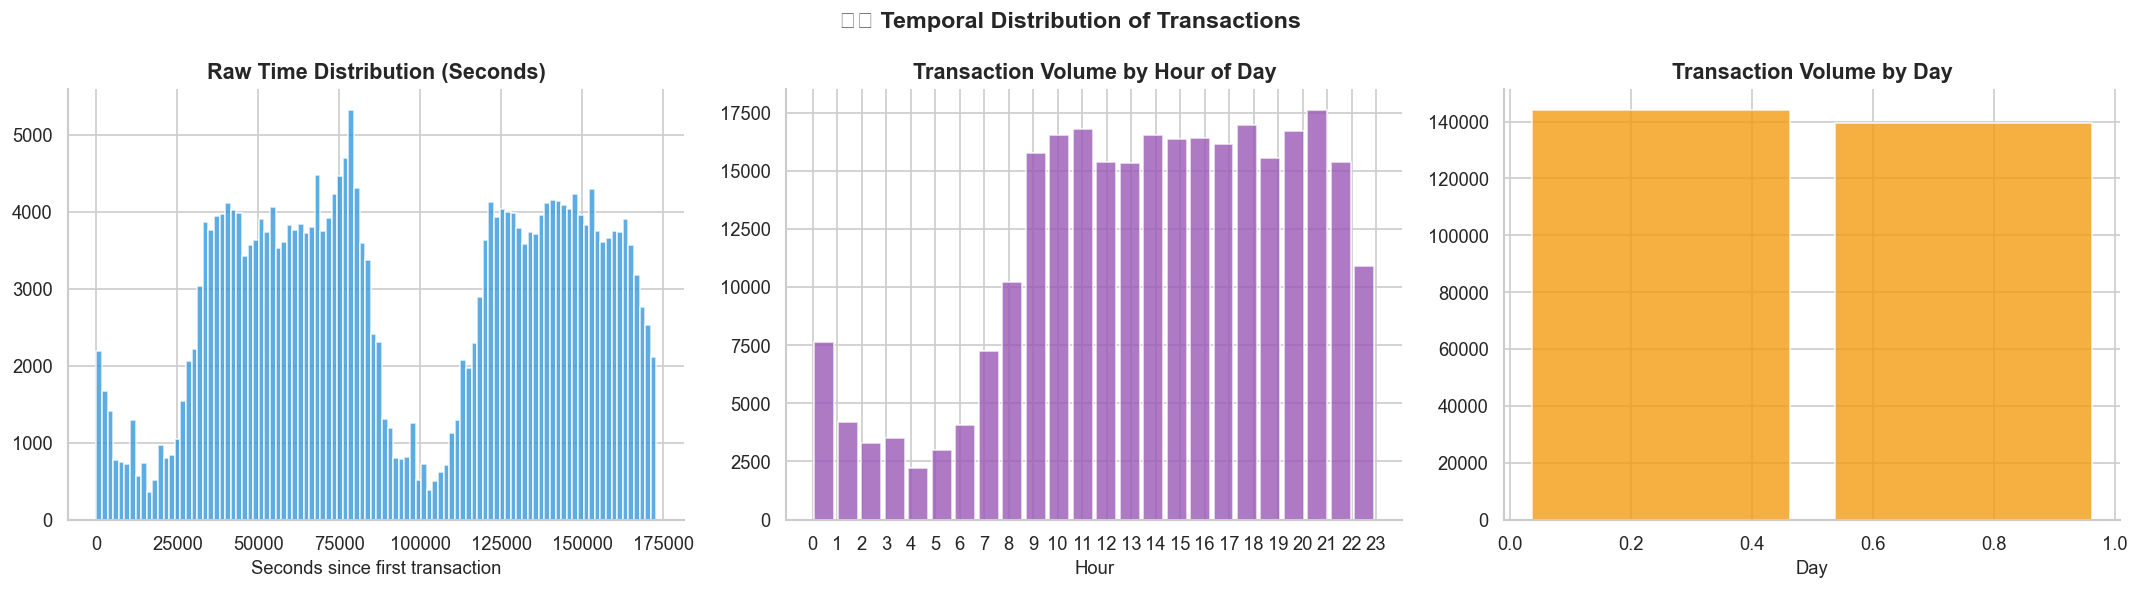

In [9]:
df["hour"] = (df["Time"] // 3600) % 24
df["day"]  = (df["Time"] // (3600 * 24)).astype(int)

print(f"Time range     : {df['Time'].min():.0f} — {df['Time'].max():.0f} seconds")
print(f"Hours covered  : {df['Time'].max() / 3600:.1f} hours")
print(f"Days covered   : {df['Time'].max() / 86400:.1f} days")
print(f"Unique hours   : {df['hour'].nunique()}")
print(f"Unique days    : {df['day'].nunique()}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Raw time
axes[0].hist(df["Time"], bins=100, color=ACCENT_COLOR, alpha=0.8, edgecolor="white")
axes[0].set_title("Raw Time Distribution (Seconds)")
axes[0].set_xlabel("Seconds since first transaction")

# Hour of day
axes[1].hist(df["hour"], bins=24, color="#9B59B6", alpha=0.8, edgecolor="white", rwidth=0.85)
axes[1].set_title("Transaction Volume by Hour of Day")
axes[1].set_xlabel("Hour")
axes[1].set_xticks(range(0, 24))

# Day
axes[2].hist(df["day"], bins=df["day"].nunique(), color=WARN_COLOR, alpha=0.8,
             edgecolor="white", rwidth=0.85)
axes[2].set_title("Transaction Volume by Day")
axes[2].set_xlabel("Day")

plt.suptitle("⏱️ Temporal Distribution of Transactions",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

📌 **Observation:**

- The data covers **exactly 48.0 hours (2 days)** and all 24 hours of the day. Volume shows **one broad daytime plateau (hours 9–22, ≈ 15–17.5k transactions per hour)** with a clear overnight trough (hours 1–6; minimum **2,204 at 04:00**) and a smaller bump at hour 0 — it is not bimodal.
- Caveat: `Time` is *seconds since the first transaction*, so `hour` is relative to the capture start. The trough at hours 1–6 suggests the capture started close to midnight local time, but this is an assumption.
- Volume is similar across both days — no anomaly in the raw time distribution.

💡 **Pipeline decision:** Raw `Time` is dropped after engineering `hour` and `day`. Cyclic `sin/cos` encoding is applied to `hour` in `load_and_engineer()` so that 23:00 and 00:00 are adjacent, not 23 hours apart.

---
## Step 10 — Fraud Rate by Hour of Day
---
**Why:** Volume plots alone don't reveal fraud risk — we need fraud *rate* per hour. A low-volume hour with a high fraud rate is more dangerous than a high-volume hour with normal fraud rate. This directly informs monitoring alert thresholds.  

**Business insight:** Late-night / early-morning hours typically show elevated fraud rates because human transaction monitoring is reduced and genuine customers make fewer purchases — any transaction is inherently more suspicious.


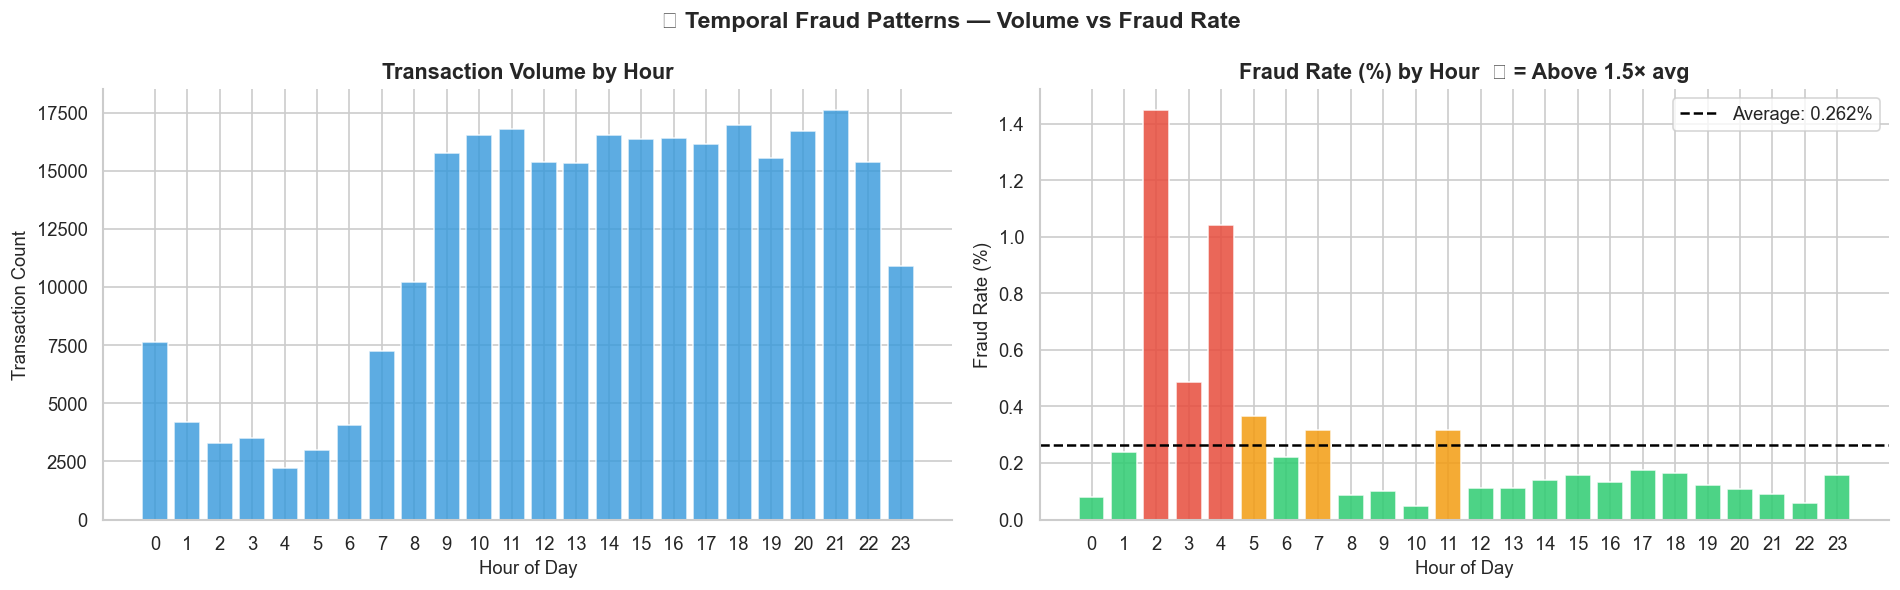

Peak fraud rate hour : 02:00  (rate=1.451%,  n=3,308)
Lowest volume hour   : 04:00  (n=2,204)


In [10]:
hourly = df.groupby("hour").agg(
    total  = ("Class", "count"),
    frauds = ("Class", "sum")
).reset_index()
hourly["fraud_rate"] = (hourly["frauds"] / hourly["total"] * 100).round(3)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Volume
axes[0].bar(hourly["hour"], hourly["total"], color=ACCENT_COLOR, alpha=0.8, edgecolor="white")
axes[0].set_title("Transaction Volume by Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Transaction Count")
axes[0].set_xticks(range(0, 24))

# Fraud rate
bar_colors = [FRAUD_COLOR if r > hourly["fraud_rate"].mean() * 1.5 else WARN_COLOR
              if r > hourly["fraud_rate"].mean() else LEGIT_COLOR
              for r in hourly["fraud_rate"]]
axes[1].bar(hourly["hour"], hourly["fraud_rate"], color=bar_colors, alpha=0.85, edgecolor="white")
axes[1].axhline(hourly["fraud_rate"].mean(), color="black", linestyle="--", linewidth=1.5,
                label=f"Average: {hourly['fraud_rate'].mean():.3f}%")
axes[1].set_title("Fraud Rate (%) by Hour  🔴 = Above 1.5× avg")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Fraud Rate (%)")
axes[1].set_xticks(range(0, 24))
axes[1].legend()

plt.suptitle("🕐 Temporal Fraud Patterns — Volume vs Fraud Rate",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

peak_hour = hourly.loc[hourly["fraud_rate"].idxmax()]
low_hour  = hourly.loc[hourly["total"].idxmin()]
print(f"Peak fraud rate hour : {int(peak_hour['hour']):02d}:00  "
      f"(rate={peak_hour['fraud_rate']:.3f}%,  n={int(peak_hour['total']):,})")
print(f"Lowest volume hour   : {int(low_hour['hour']):02d}:00  (n={int(low_hour['total']):,})")

📌 **Observation:**

- Fraud rate **peaks at 02:00 with 1.451%** (n = 3,308) — about **8.7× the overall 0.167%**. Hours 3 and 4 are also elevated (≈ 0.5% and ≈ 1.0%), exactly where volume is at its lowest.
- Daytime hours (8–22) mostly sit at 0.05–0.17%; a few mid-day hours (7 and 11) reach ≈ 0.3%.
- The dashed "average" line (0.262%) is the mean of the 24 hourly rates, not the overall rate, so the "1.5× avg" red flag is conservative. The night-hour rates rest on small counts (≈ 48 frauds at 02:00), so their exact size is uncertain even though the pattern is clear.

💡 **Pipeline decision:** `hour_sin` and `hour_cos` encode this pattern cyclically. For tree models a simple `is_night_risk` flag (hours 2–4) is a worthwhile optional add-on, since cyclic features need several splits to isolate a three-hour window. The monitoring dashboard tracks fraud rate by hour and alerts when it exceeds the thresholds observed here.

---
## Step 11 — Fraud Rate by Day
---
**Why:** Day-level analysis reveals if fraud concentrates on specific calendar days. With only 2 days in this dataset, the comparison is limited — but the methodology generalises to longer time windows in production monitoring.  

**Business insight:** In production, monitoring day-over-day fraud rate is a key alerting signal. A sudden spike from Day N's baseline triggers a model retraining review and fraud team escalation.


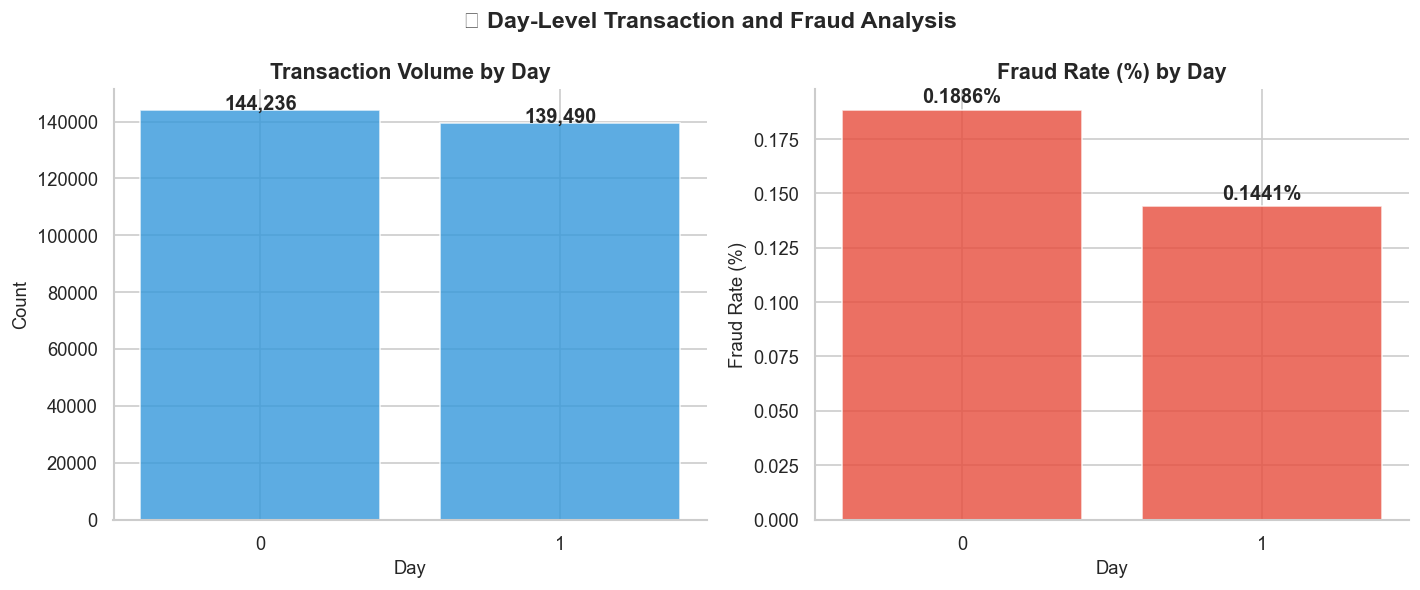

 day  total  frauds  fraud_rate
   0 144236     272      0.1886
   1 139490     201      0.1441


In [11]:
daily = df.groupby("day").agg(
    total  = ("Class", "count"),
    frauds = ("Class", "sum")
).reset_index()
daily["fraud_rate"] = (daily["frauds"] / daily["total"] * 100).round(4)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(daily["day"].astype(str), daily["total"],
            color=ACCENT_COLOR, alpha=0.8, edgecolor="white")
axes[0].set_title("Transaction Volume by Day")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Count")
for i, row in daily.iterrows():
    axes[0].text(i, row["total"] + 200, f"{int(row['total']):,}",
                 ha="center", fontweight="bold")

axes[1].bar(daily["day"].astype(str), daily["fraud_rate"],
            color=FRAUD_COLOR, alpha=0.8, edgecolor="white")
axes[1].set_title("Fraud Rate (%) by Day")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Fraud Rate (%)")
for i, row in daily.iterrows():
    axes[1].text(i, row["fraud_rate"] + 0.003, f"{row['fraud_rate']:.4f}%",
                 ha="center", fontweight="bold")

plt.suptitle("📅 Day-Level Transaction and Fraud Analysis",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(daily[["day","total","frauds","fraud_rate"]].to_string(index=False))

📌 **Observation:**

- Day 0: 144,236 transactions, 272 frauds (**0.1886%**). Day 1: 139,490 transactions, 201 frauds (**0.1441%**). The day-0 rate is about 31% higher, but with only two days it is impossible to separate noise from a genuine trend.
- Volumes are very similar across the two days.

💡 **Pipeline decision:** The `day` column is used to build the daily aggregate features in `build_fraud_features()` (`txn_count_day`, `avg_amount_day`, `amount_deviation`). ⚠️ It should **not** be fed to the model as a raw predictor: it only takes the values 0 and 1 here and would be out of range for any later date. The 0.19% / 0.14% pair serves as the baseline reference for PSI drift monitoring.

---
## Step 12 — Amount Distribution — Fraud vs Legitimate
---
**Why:** Overlapping density plots directly answer "Where in the Amount range are fraudulent transactions concentrated?" Non-overlapping regions are high-signal zones. This directly validates or challenges the `Amount > 5000 → BLOCK_RULE` in the production rule engine.  

**Business insight:** Card testers often start with micro-transactions ($1–$10) to verify the card is active before making large purchases. High-value ($1000+) transactions are targeted because they maximise the payout per successful fraud.


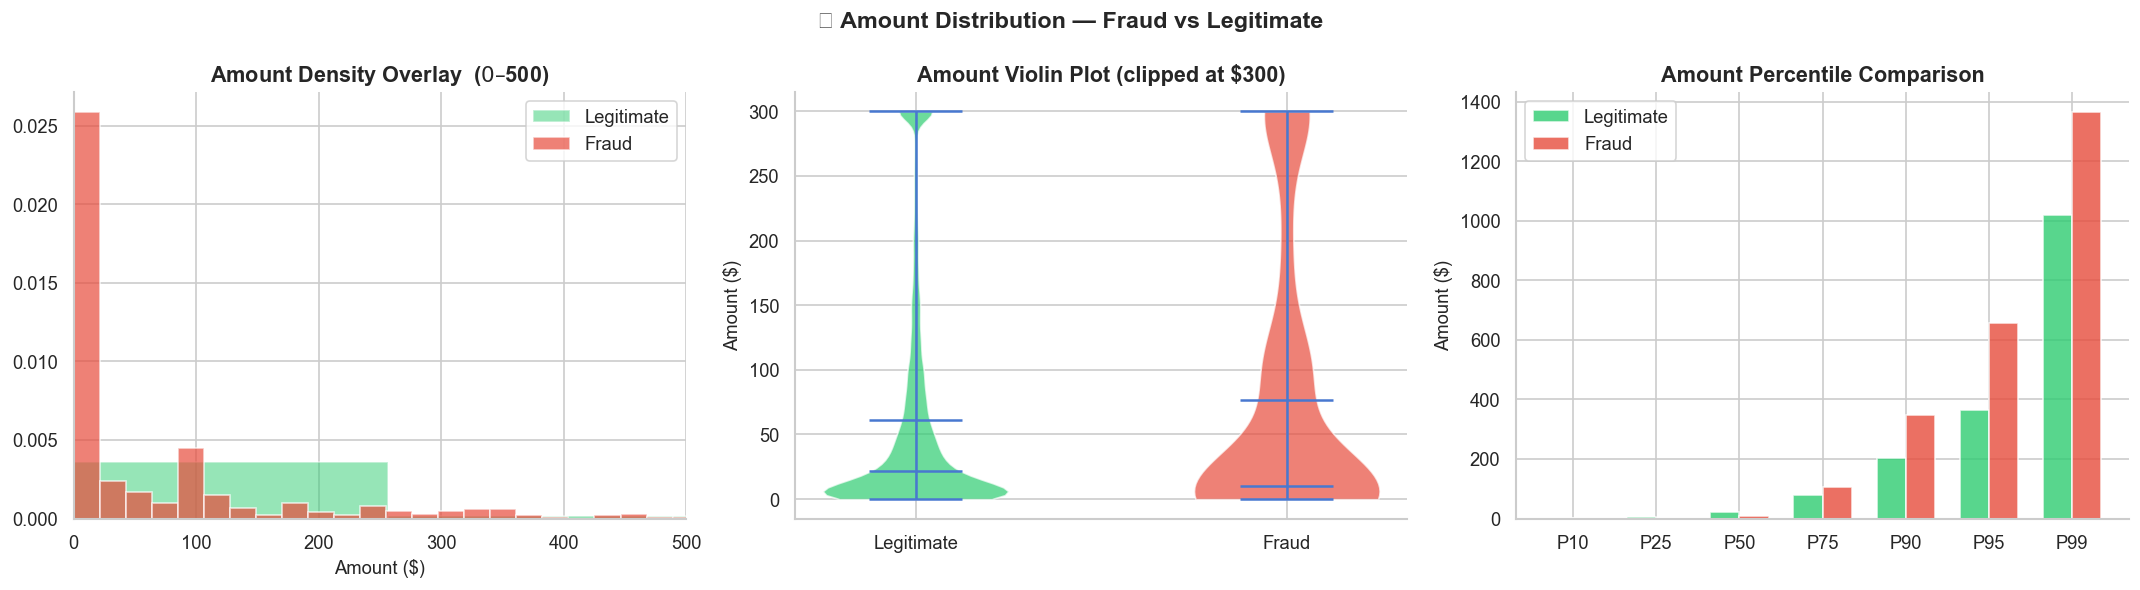

Amount Percentiles by Class:
            Legitimate    Fraud
Percentile                     
10                1.00     0.76
25                5.67     1.00
50               22.00     9.82
75               77.46   105.89
90              203.00   348.65
95              365.00   655.82
99             1018.06  1364.14


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Density overlay — zoomed to $0-$500
axes[0].hist(legit_df["Amount"], bins=100, alpha=0.5, color=LEGIT_COLOR,
             label="Legitimate", density=True)
axes[0].hist(fraud_df["Amount"], bins=100, alpha=0.7, color=FRAUD_COLOR,
             label="Fraud",      density=True)
axes[0].set_xlim(0, 500)
axes[0].set_title("Amount Density Overlay  ($0–$500)")
axes[0].set_xlabel("Amount ($)")
axes[0].legend()

# Violin
vp = axes[1].violinplot(
    [legit_df["Amount"].clip(0, 300).tolist(),
     fraud_df["Amount"].clip(0, 300).tolist()],
    positions=[1, 2], showmedians=True, showmeans=True
)
for i, body in enumerate(vp["bodies"]):
    body.set_facecolor([LEGIT_COLOR, FRAUD_COLOR][i])
    body.set_alpha(0.7)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["Legitimate", "Fraud"])
axes[1].set_title("Amount Violin Plot (clipped at $300)")
axes[1].set_ylabel("Amount ($)")

# Percentiles comparison
pcts = [10, 25, 50, 75, 90, 95, 99]
legit_pct = [np.percentile(legit_df["Amount"], p) for p in pcts]
fraud_pct = [np.percentile(fraud_df["Amount"], p) for p in pcts]
x = np.arange(len(pcts))
w = 0.35
axes[2].bar(x - w/2, legit_pct, w, label="Legitimate", color=LEGIT_COLOR, alpha=0.8)
axes[2].bar(x + w/2, fraud_pct, w, label="Fraud",      color=FRAUD_COLOR, alpha=0.8)
axes[2].set_xticks(x)
axes[2].set_xticklabels([f"P{p}" for p in pcts])
axes[2].set_title("Amount Percentile Comparison")
axes[2].set_ylabel("Amount ($)")
axes[2].legend()

plt.suptitle("💰 Amount Distribution — Fraud vs Legitimate",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("Amount Percentiles by Class:")
pct_df = pd.DataFrame({
    "Percentile": pcts,
    "Legitimate":  legit_pct,
    "Fraud":       fraud_pct,
}).set_index("Percentile")
print(pct_df.round(2).to_string())

📌 **Observation:**

- Percentiles show a **crossover**: fraud is lower in the lower half (p25: $1.00 vs $5.67; median: $9.82 vs $22.00) but **higher in the upper tail** (p75: $105.89 vs $77.46; p90: $348.65 vs $203.00; p95: $655.82 vs $365.00; p99: $1,364.14 vs $1,018.06).
- The violin plot shows the same picture: a thick mass of micro-amounts plus a heavier upper tail than legitimate spend.
- The density overlay confirms that no amount range is fraud-only — amount alone cannot separate the classes.

💡 **Pipeline decision:** `log1p(Amount)` is used for linear models (compresses the tail, skewness 16.98 → 0.16 — see Step 13); tree models receive the clipped raw value. Because fraud shows both a micro-amount regime and a high-amount regime, the `Amount > 5000 → BLOCK_RULE` is re-tested in Step 19.

---
## Step 13 — Log-Amount Transformation
---
**Why:** Amount skewness of 17+ violates normality assumptions of linear models. `log1p` (log(x+1)) compresses the right tail, handles zero-amount transactions safely, and produces a near-Gaussian distribution that benefits StandardScaler.  

**Business insight:** Log-transforming amount before training is standard practice in payment ML systems. It ensures a $100 increase at the $100 level is treated proportionally to a $10,000 increase at the $10,000 level — which matches real financial risk intuition.


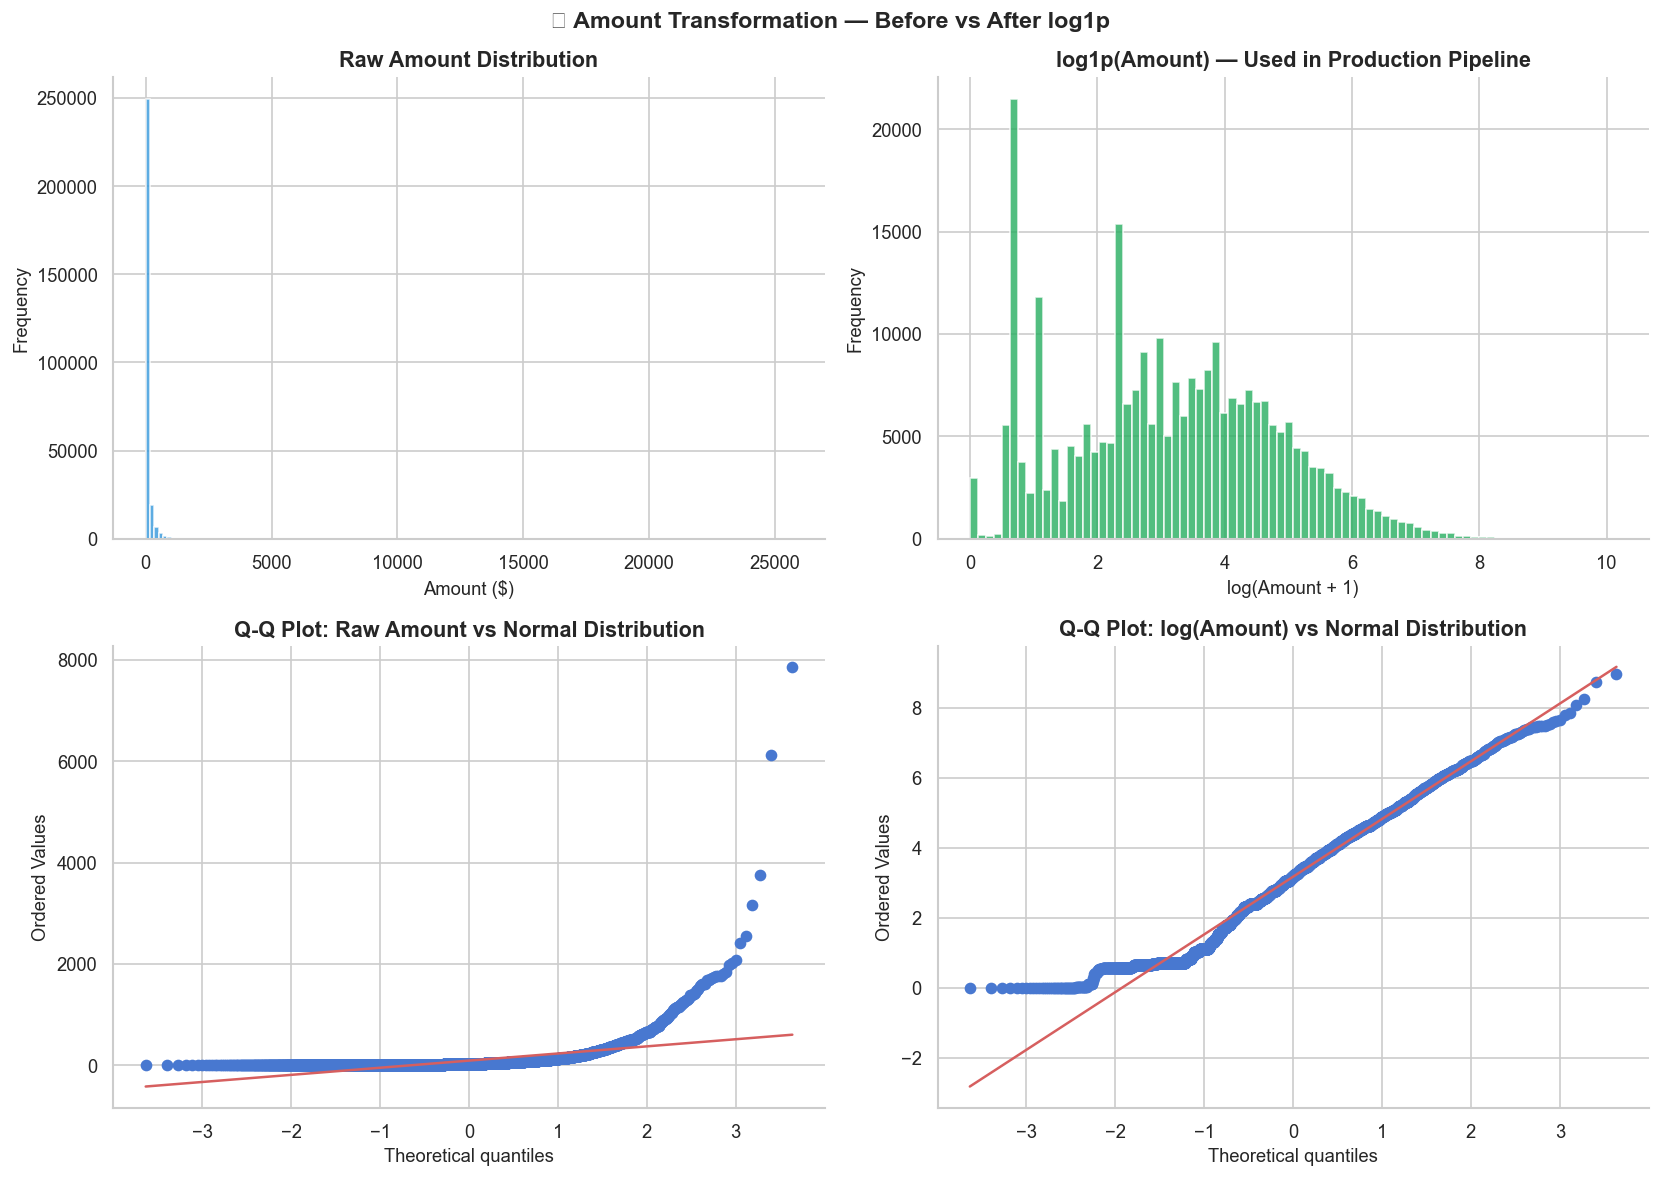

Raw Amount  — skewness:  16.9788  kurtosis: 844.4713
Log Amount  — skewness:   0.1614  kurtosis: -0.6413

Interpretation: Skewness closer to 0 = more symmetric = better for linear models


In [13]:
df["log_amount"] = np.log1p(df["Amount"])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Raw amount histogram
axes[0, 0].hist(df["Amount"], bins=150, color=ACCENT_COLOR, alpha=0.8, edgecolor="white")
axes[0, 0].set_title("Raw Amount Distribution")
axes[0, 0].set_xlabel("Amount ($)")
axes[0, 0].set_ylabel("Frequency")

# Log amount histogram
axes[0, 1].hist(df["log_amount"], bins=80, color="#27AE60", alpha=0.8, edgecolor="white")
axes[0, 1].set_title("log1p(Amount) — Used in Production Pipeline")
axes[0, 1].set_xlabel("log(Amount + 1)")
axes[0, 1].set_ylabel("Frequency")

# Q-Q raw
stats.probplot(df["Amount"].sample(5000, random_state=42), dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Q-Q Plot: Raw Amount vs Normal Distribution")

# Q-Q log
stats.probplot(df["log_amount"].sample(5000, random_state=42), dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q Plot: log(Amount) vs Normal Distribution")

plt.suptitle("📊 Amount Transformation — Before vs After log1p",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Raw Amount  — skewness: {df['Amount'].skew():>8.4f}  kurtosis: {df['Amount'].kurtosis():.4f}")
print(f"Log Amount  — skewness: {df['log_amount'].skew():>8.4f}  kurtosis: {df['log_amount'].kurtosis():.4f}")
print()
print("Interpretation: Skewness closer to 0 = more symmetric = better for linear models")

📌 **Observation:**

- Log-transforming `Amount` reduces skewness from **16.98 to 0.16** and kurtosis from **844.5 to −0.64**.
- The Q-Q plot for `log_amount` follows the diagonal closely, whereas the raw-amount Q-Q plot departs sharply in both tails.

💡 **Pipeline decision:** `load_and_engineer()` applies `log1p` to `Amount` before the preprocessor runs. The original `Amount_original` is retained separately for **cost-sensitive evaluation** — the false-negative loss must be calculated in real dollars, not log-dollars.

---
## Step 14 — PCA Feature Distributions (V1–V28)
---
**Why:** Even though V1–V28 are anonymised PCA components, their distributions relative to the fraud class reveal which components carry the strongest signal. Wide separation between fraud and legit distributions = strong predictor.  

**Business insight:** PCA components are ordered by variance explained. Lower-numbered components (V1, V2) capture the most variance in the original transaction data. Features with visually separated fraud/legit distributions are prime candidates for SelectKBest.


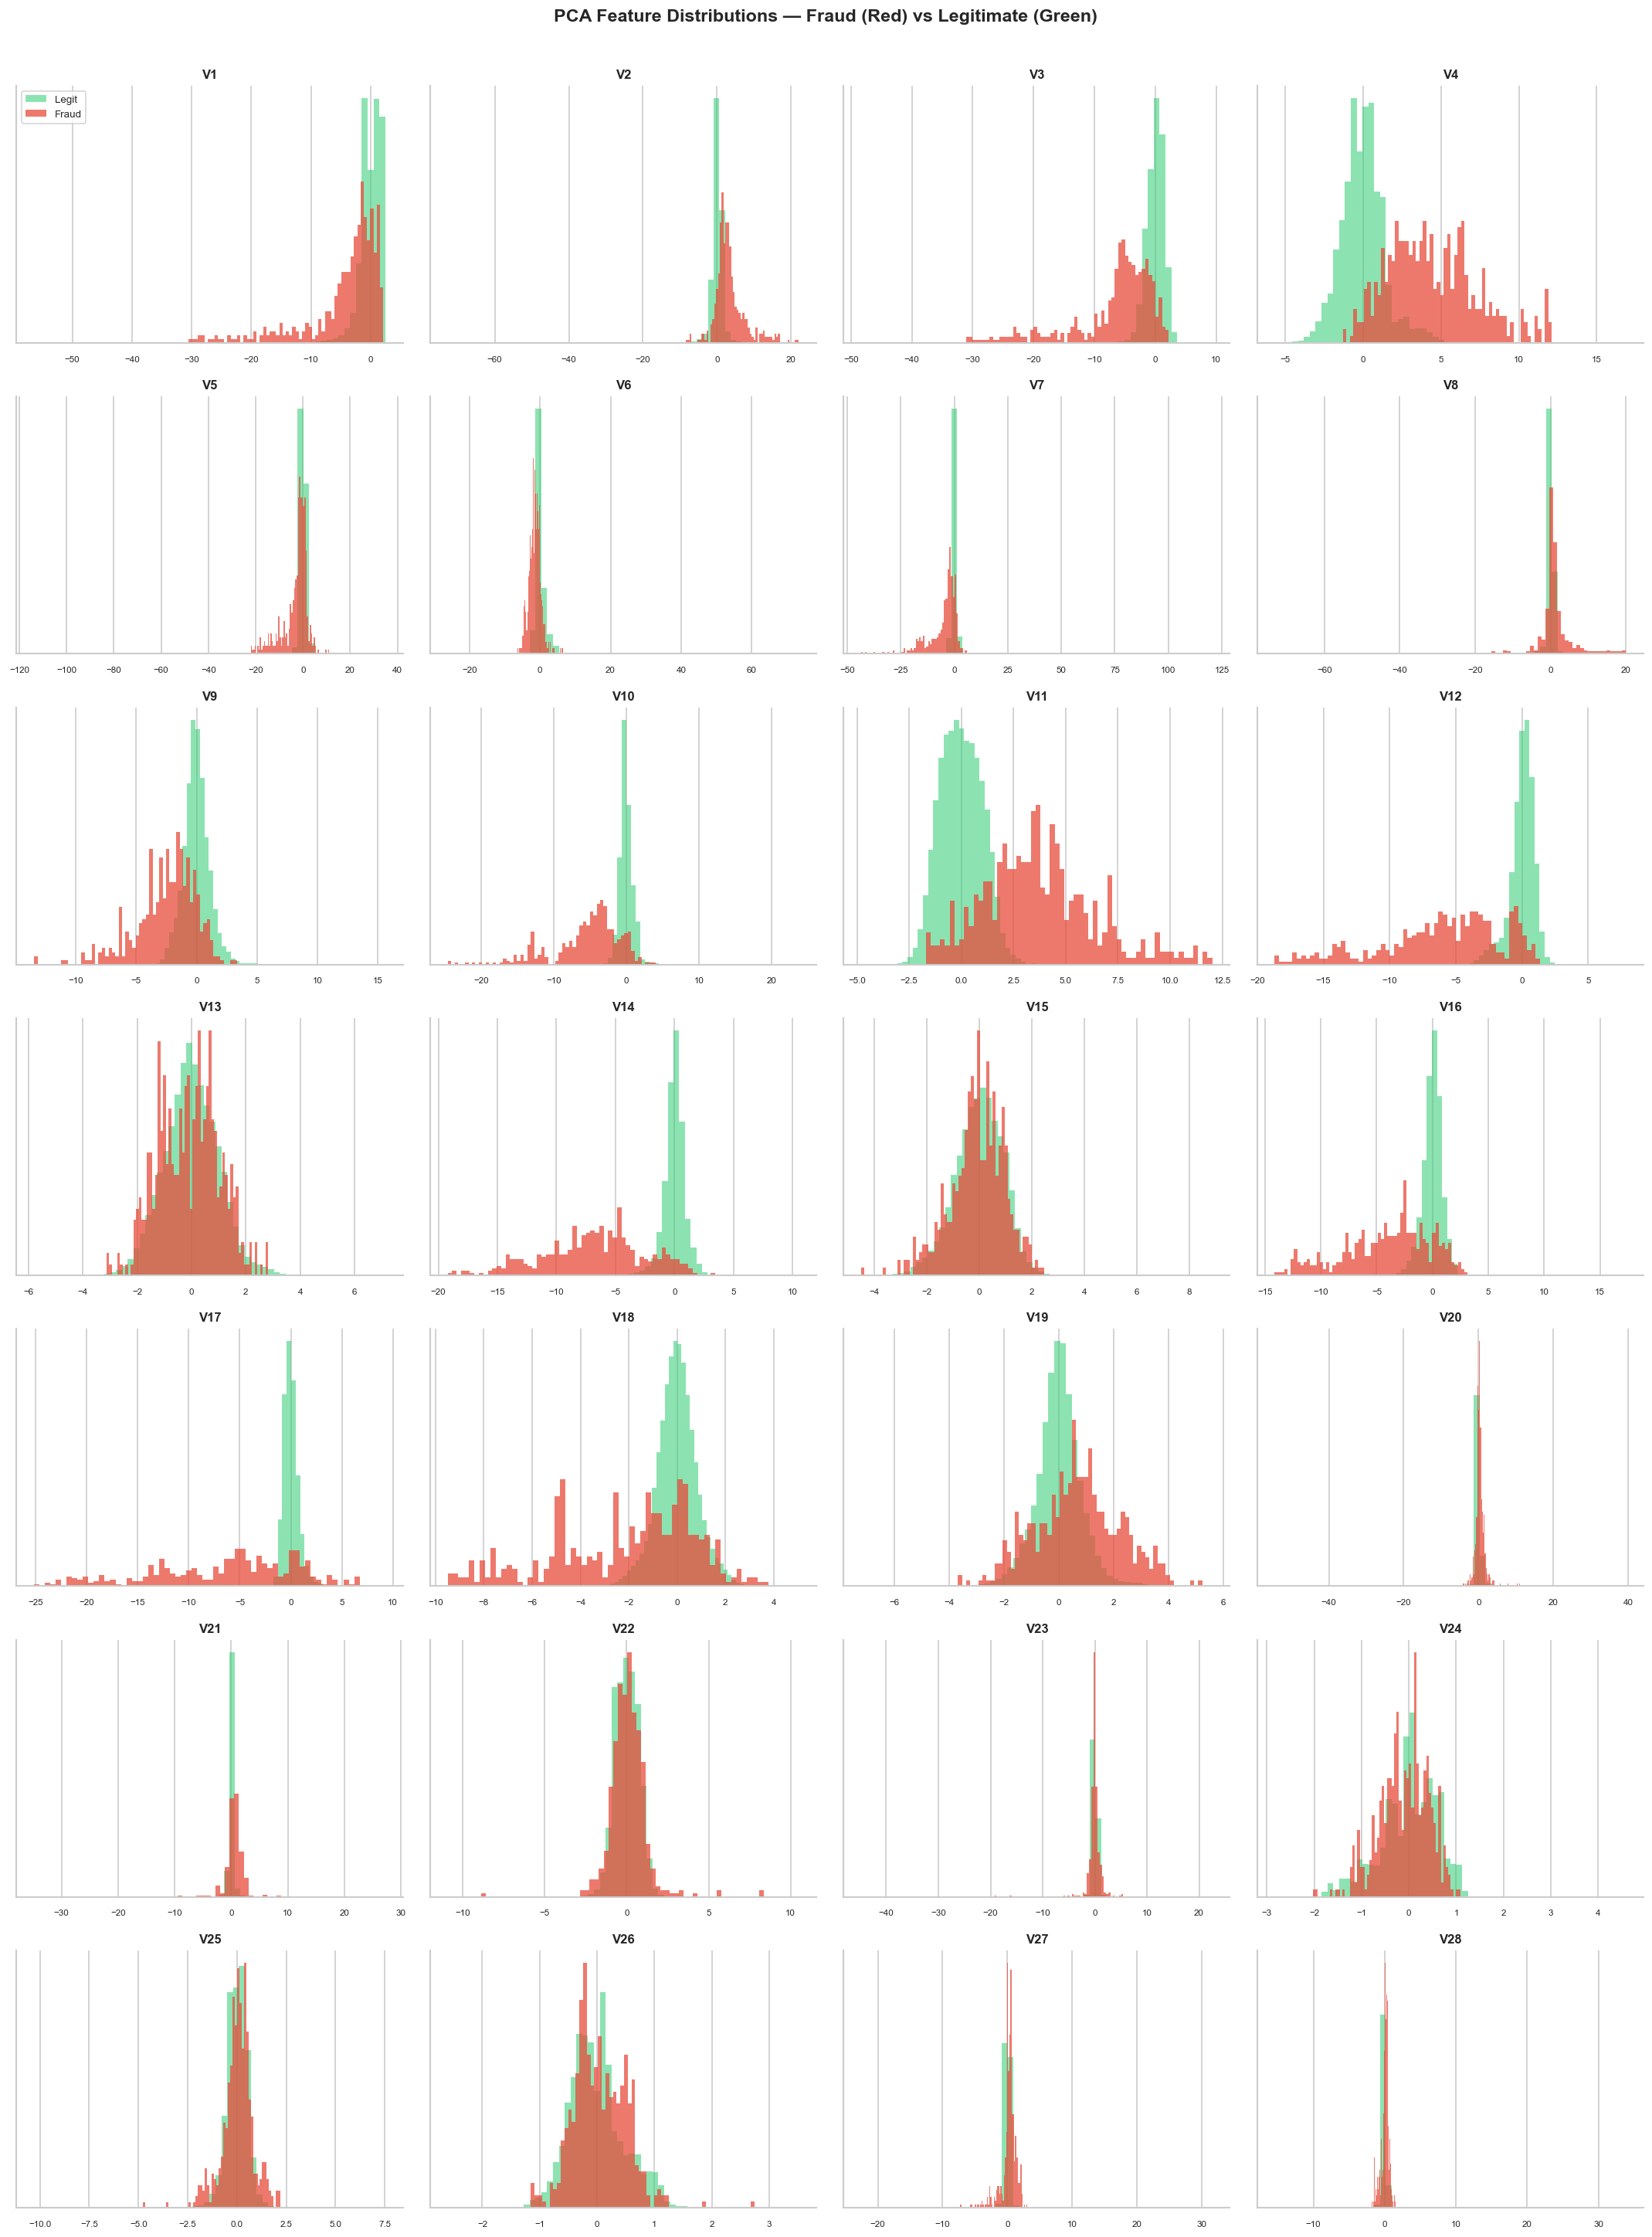

Top 10 features with greatest visual separation (|fraud_mean - legit_mean|):
  V14  : 6.8476
  V3   : 6.7425
  V17  : 6.4742
  V12  : 6.1127
  V10  : 5.4609
  V7   : 5.1864
  V1   : 4.5117
  V4   : 4.4830
  V16  : 4.0088
  V11  : 3.7224


In [14]:
v_cols = [f"V{i}" for i in range(1, 29)]

fraud_v  = df[df["Class"] == 1]
legit_v  = df[df["Class"] == 0]

fig, axes = plt.subplots(7, 4, figsize=(18, 24))
axes = axes.flatten()

for i, col in enumerate(v_cols):
    axes[i].hist(legit_v[col], bins=60, alpha=0.55, color=LEGIT_COLOR,
                 label="Legit", density=True, edgecolor="none")
    axes[i].hist(fraud_v[col], bins=60, alpha=0.75, color=FRAUD_COLOR,
                 label="Fraud", density=True, edgecolor="none")
    axes[i].set_title(col, fontsize=10, fontweight="bold")
    axes[i].tick_params(labelsize=7)
    axes[i].set_yticks([])
    if i == 0:
        axes[i].legend(fontsize=8)

plt.suptitle("PCA Feature Distributions — Fraud (Red) vs Legitimate (Green)",
             fontsize=14, fontweight="bold", y=1.005)
plt.tight_layout()
plt.show()

# Summary of visual separation
sep_scores = {col: abs(fraud_v[col].mean() - legit_v[col].mean()) for col in v_cols}
top_sep = sorted(sep_scores, key=sep_scores.get, reverse=True)[:10]
print("Top 10 features with greatest visual separation (|fraud_mean - legit_mean|):")
for f in top_sep:
    print(f"  {f:<5}: {sep_scores[f]:.4f}")

📌 **Observation:**

- Ranked by |fraud mean − legit mean|, the strongest PCA features are **V14 (6.85), V3 (6.74), V17 (6.47), V12 (6.11) and V10 (5.46)**, followed by V7, V1, V4, V16 and V11.
- In the histograms, legitimate transactions form a narrow spike around 0 for every component, while fraud is broader and shifted — towards negative values for most strong features and towards positive values for `V4` and `V11`.
- `V13`, `V15`, `V22`, `V23`, `V25`, `V26` and `V28` show almost no separation.

💡 **Pipeline decision:** `SelectKBest(mutual_info_classif, k=20)` retains the most informative features automatically. This EDA predicts it will keep V14, V3, V17, V12 and V10 and drop the low-signal group. Note that |Δmean| is not scale-normalised, so the mutual-information ranking may order the middle of the list differently.

---
## Step 15 — Top PCA Features — Fraud Signal Strength
---
**Why:** Quantifying signal strength across all 28 PCA features gives a ranked importance list before model training. This pre-validation of feature utility increases confidence in SelectKBest results and catches potential data issues early.  

**Business insight:** Features with strong fraud signal are the ones that most distinguish fraud from legitimate transaction profiles. High signal features = what the bank's fraud team should focus rule-engine thresholds on.


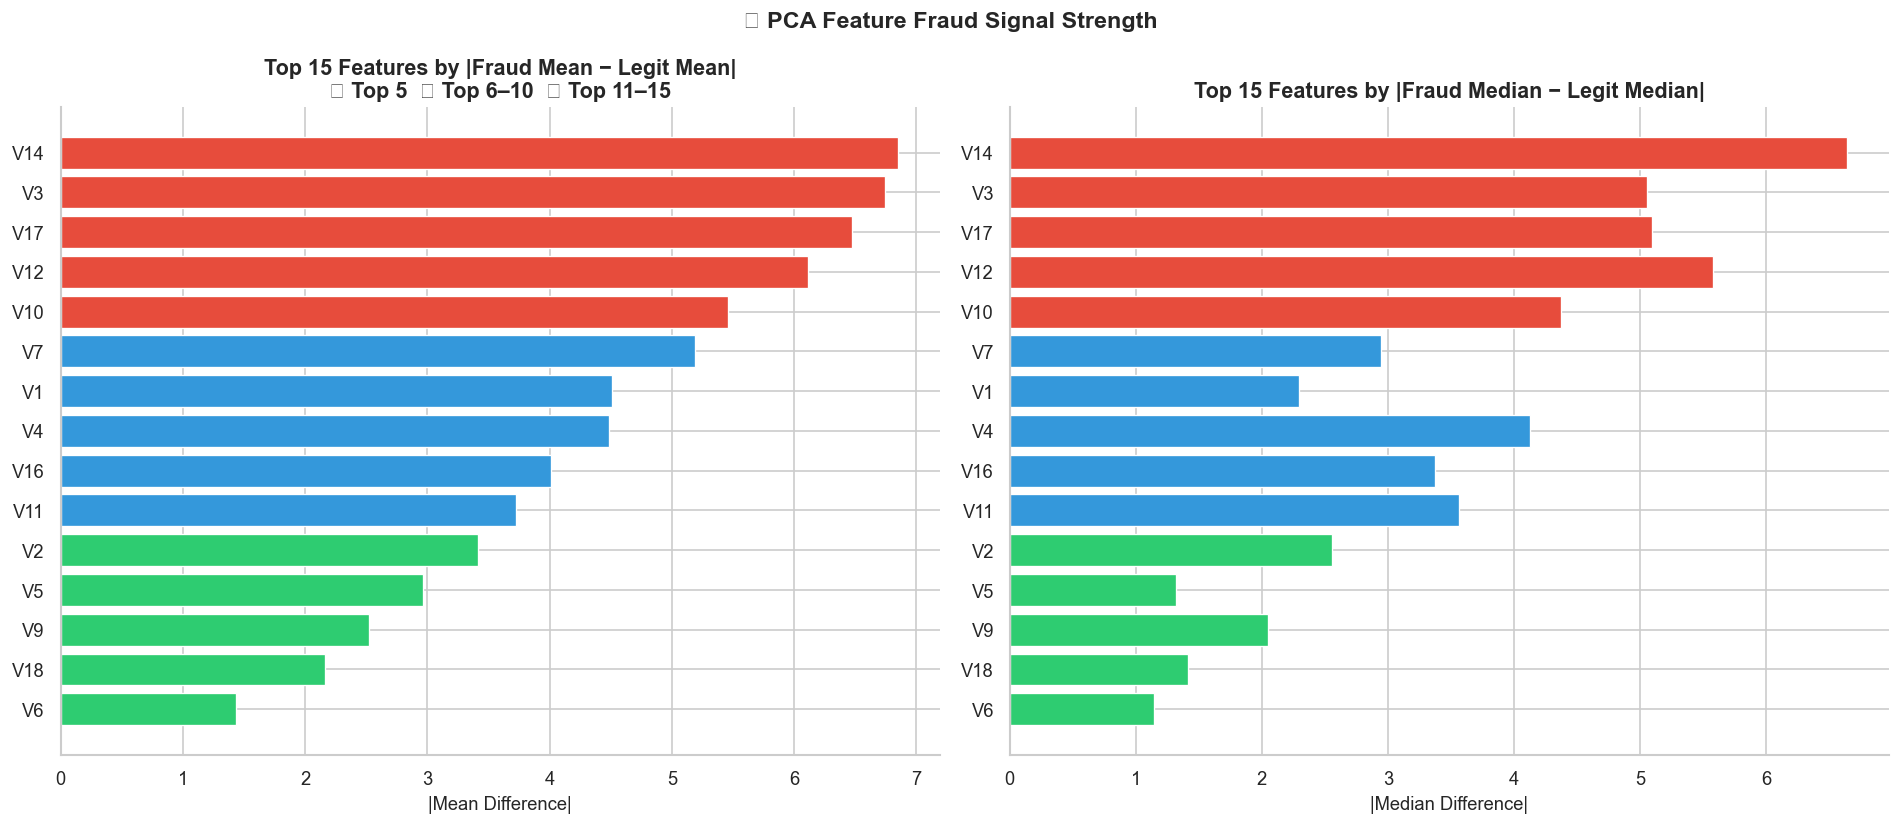

Top 10 Fraud Signal Features (Mann-Whitney U test confirms statistical significance):
feature  mean_diff  median_diff  mw_pvalue  fraud_mean  legit_mean
    V14     6.8476       6.6420        0.0     -6.8359      0.0117
     V3     6.7425       5.0576        0.0     -6.7296      0.0129
    V17     6.4742       5.0925        0.0     -6.4633      0.0110
    V12     6.1127       5.5779        0.0     -6.1033      0.0095
    V10     5.4609       4.3742        0.0     -5.4533      0.0077
     V7     5.1864       2.9437        0.0     -5.1759      0.0104
     V1     4.5117       2.2943        0.0     -4.4983      0.0134
     V4     4.4830       4.1246        0.0      4.4726     -0.0104
    V16     4.0088       3.3710        0.0     -4.0010      0.0078
    V11     3.7224       3.5602        0.0      3.7163     -0.0060

Low-signal features (mean_diff < 0.1): ['V23', 'V13', 'V22', 'V28', 'V15', 'V26', 'V25'] — likely dropped by SelectKBest


In [15]:
from scipy.stats import mannwhitneyu

signal_stats = []
for col in v_cols:
    fraud_vals = fraud_v[col].values
    legit_vals = legit_v[col].values

    mean_diff    = abs(fraud_vals.mean() - legit_vals.mean())
    median_diff  = abs(np.median(fraud_vals) - np.median(legit_vals))
    stat, pvalue = mannwhitneyu(fraud_vals, legit_vals, alternative="two-sided")

    signal_stats.append({
        "feature":      col,
        "mean_diff":    round(mean_diff,  4),
        "median_diff":  round(median_diff, 4),
        "mw_pvalue":    round(pvalue, 6),
        "fraud_mean":   round(fraud_vals.mean(), 4),
        "legit_mean":   round(legit_vals.mean(), 4),
    })

sig_df = pd.DataFrame(signal_stats).sort_values("mean_diff", ascending=False).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

TOP = 15
colors = [FRAUD_COLOR if i < 5 else ACCENT_COLOR if i < 10 else LEGIT_COLOR
          for i in range(TOP)]

axes[0].barh(sig_df["feature"][:TOP][::-1],
             sig_df["mean_diff"][:TOP][::-1],
             color=colors[::-1], edgecolor="white", linewidth=0.8)
axes[0].set_title(f"Top {TOP} Features by |Fraud Mean − Legit Mean|\n"
                  "🔴 Top 5  🔵 Top 6–10  🟢 Top 11–15")
axes[0].set_xlabel("|Mean Difference|")

# Median diff
axes[1].barh(sig_df["feature"][:TOP][::-1],
             sig_df["median_diff"][:TOP][::-1],
             color=colors[::-1], edgecolor="white", linewidth=0.8)
axes[1].set_title(f"Top {TOP} Features by |Fraud Median − Legit Median|")
axes[1].set_xlabel("|Median Difference|")

plt.suptitle("🔍 PCA Feature Fraud Signal Strength",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

sig_cols = ["feature", "mean_diff", "median_diff", "mw_pvalue", "fraud_mean", "legit_mean"]
print("Top 10 Fraud Signal Features (Mann-Whitney U test confirms statistical significance):")
print(sig_df[sig_cols].head(10).to_string(index=False))
print()
low_sig = sig_df[sig_df["mean_diff"] < 0.1]
print(f"Low-signal features (mean_diff < 0.1): {list(low_sig['feature'])} — likely dropped by SelectKBest")

📌 **Observation:**

- The top-5 fraud-signal features are **V14, V3, V17, V12 and V10** (mean differences 6.85 – 5.46), all highly significant in the Mann-Whitney U test (p-values print as 0.0, i.e. p < 0.001).
- Seven features fall below the 0.1 mean-difference threshold: **V23, V13, V22, V28, V15, V26, V25** — they overlap almost completely between fraud and legitimate transactions.

💡 **Pipeline decision:** `SelectKBest` with `mutual_info_classif` and `k = 20` discards the 8 weakest of the 28 PCA components (the 7 listed above plus one borderline feature), reducing model complexity without losing the high-signal components.

---
## Step 16 — Bivariate Analysis — PCA Features vs Target
---
**Why:** KDE plots for top features directly show separation per class. Unlike aggregate statistics, distributions reveal whether fraud and legit populations are separable or interleaved — which determines difficulty of classification.  

**Business insight:** A feature where fraud and legit distributions barely overlap is a gift to the model — it will naturally assign high importance to that feature. Overlapping features require the model to combine multiple weak signals.


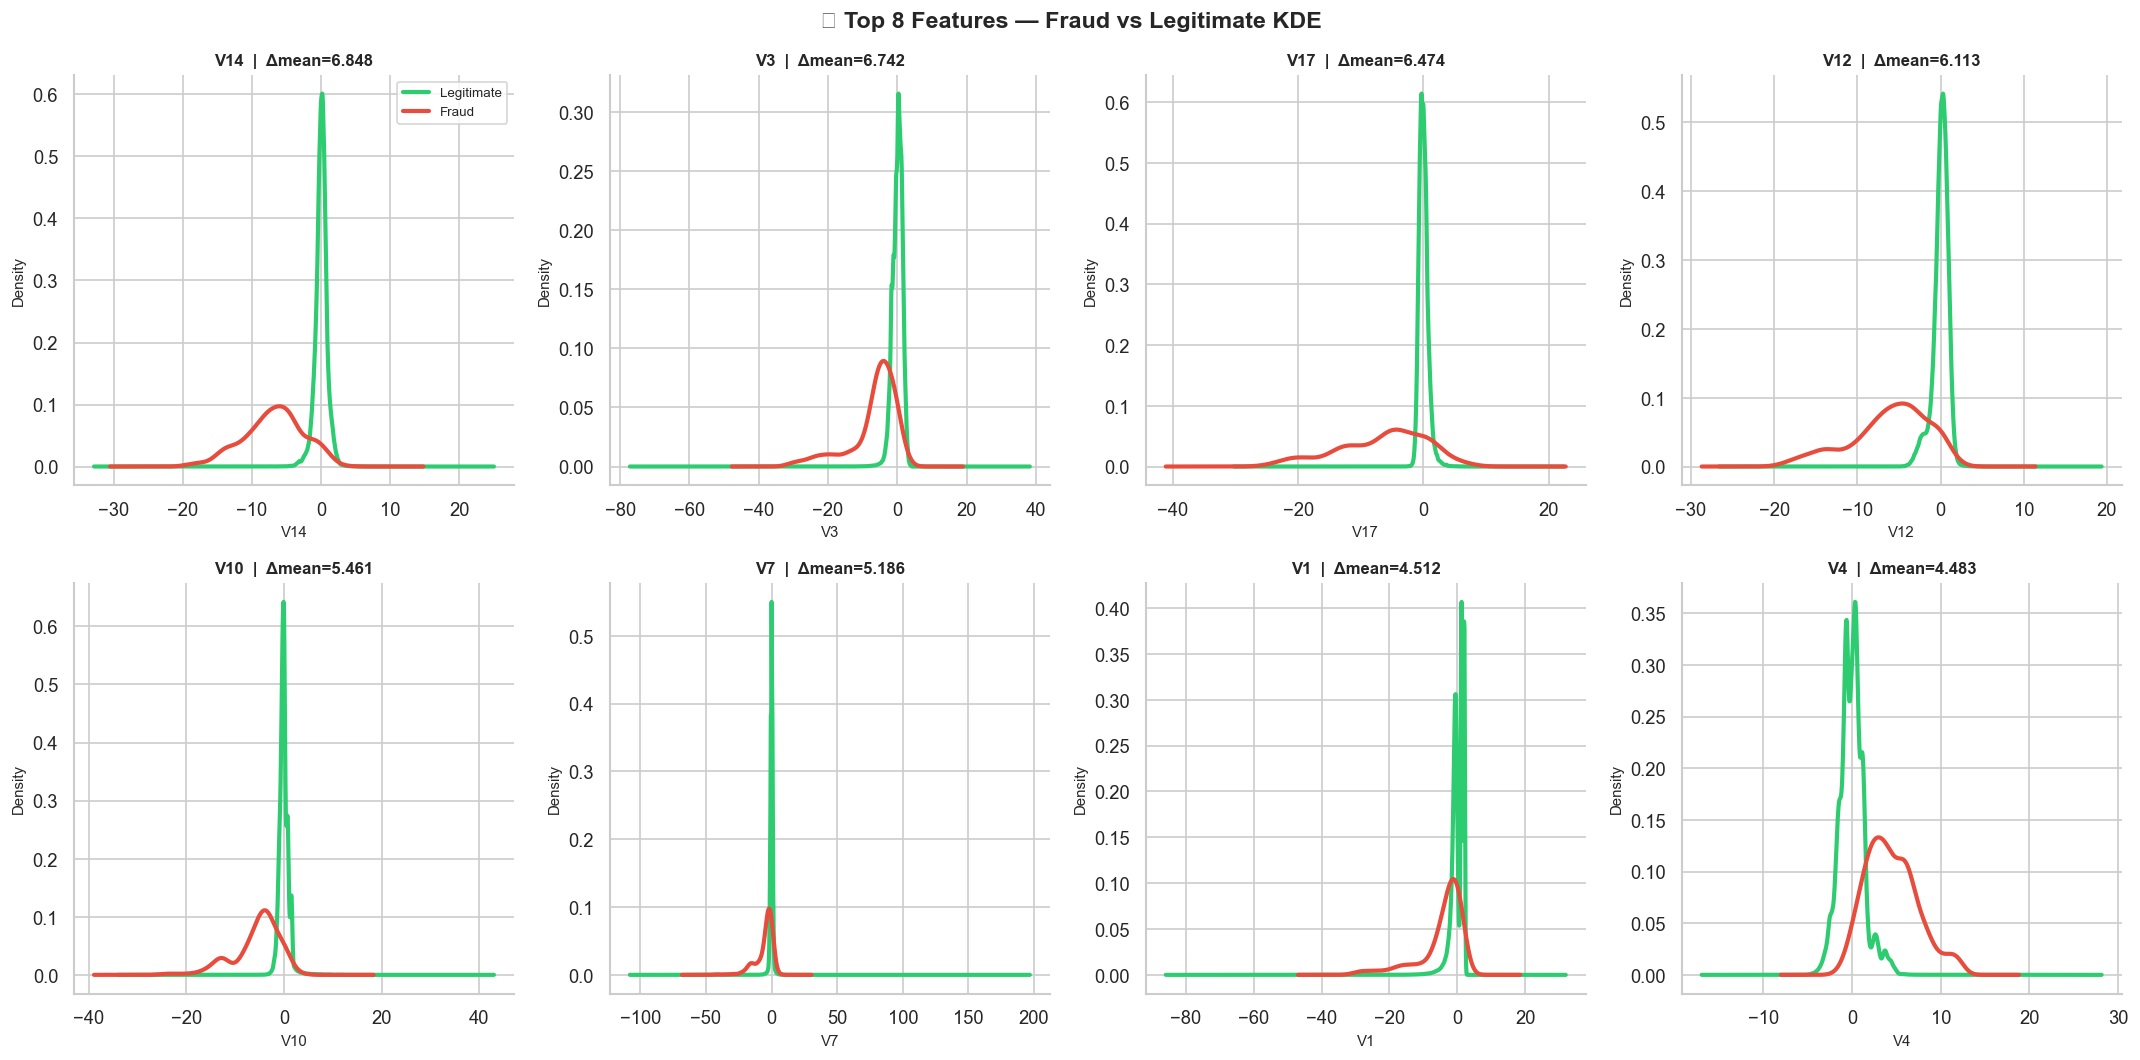

In [16]:
top_features = sig_df["feature"].head(8).tolist()

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, col in enumerate(top_features):
    # KDE
    try:
        legit_v[col].plot.kde(ax=axes[i], color=LEGIT_COLOR, linewidth=2.5,
                               label="Legitimate")
        fraud_v[col].plot.kde(ax=axes[i], color=FRAUD_COLOR, linewidth=2.5,
                               label="Fraud")
    except Exception:
        axes[i].hist(legit_v[col], bins=50, density=True, alpha=0.5,
                     color=LEGIT_COLOR, label="Legitimate")
        axes[i].hist(fraud_v[col], bins=50, density=True, alpha=0.6,
                     color=FRAUD_COLOR, label="Fraud")

    axes[i].set_title(f"{col}  |  Δmean={sig_df[sig_df['feature']==col]['mean_diff'].values[0]:.3f}",
                      fontsize=10)
    axes[i].set_xlabel(col, fontsize=9)
    axes[i].set_ylabel("Density", fontsize=9)
    if i == 0:
        axes[i].legend(fontsize=8)

plt.suptitle("📊 Top 8 Features — Fraud vs Legitimate KDE",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

📌 **Observation:**

- The 8 strongest features by mean difference are V14, V3, V17, V12, V10, V7, V1 and V4. In every panel the legitimate class is a sharp spike near 0, while fraud forms a much wider, shifted distribution — negative for V14, V3, V17, V12, V10 and V1, positive (peak around +3 to +4) for V4.
- Separation is **strong but partial**: the fraud curves still overlap the legitimate spike near 0 (especially V7 and V1), so no single feature separates the classes on its own.

💡 **Pipeline decision:** V14, V17, V12 and V3 will dominate tree-based feature importances, and they are the primary drivers of high risk scores in the SHAP explanations. Because separation is partial, the model must combine several weak and strong signals — one reason to keep a non-linear ensemble in the candidate set.

---
## Step 17 — Feature Correlation Matrix
---
**Why:** High correlation between features indicates multicollinearity — which inflates coefficient variance in logistic regression and leads to unstable feature importances. It also reveals which features carry redundant information.  

**Business insight:** PCA by construction produces orthogonal (uncorrelated) components. Any correlation observed is due to the engineered features (log_amount, hour_sin, hour_cos, day) — not the PCA features themselves.


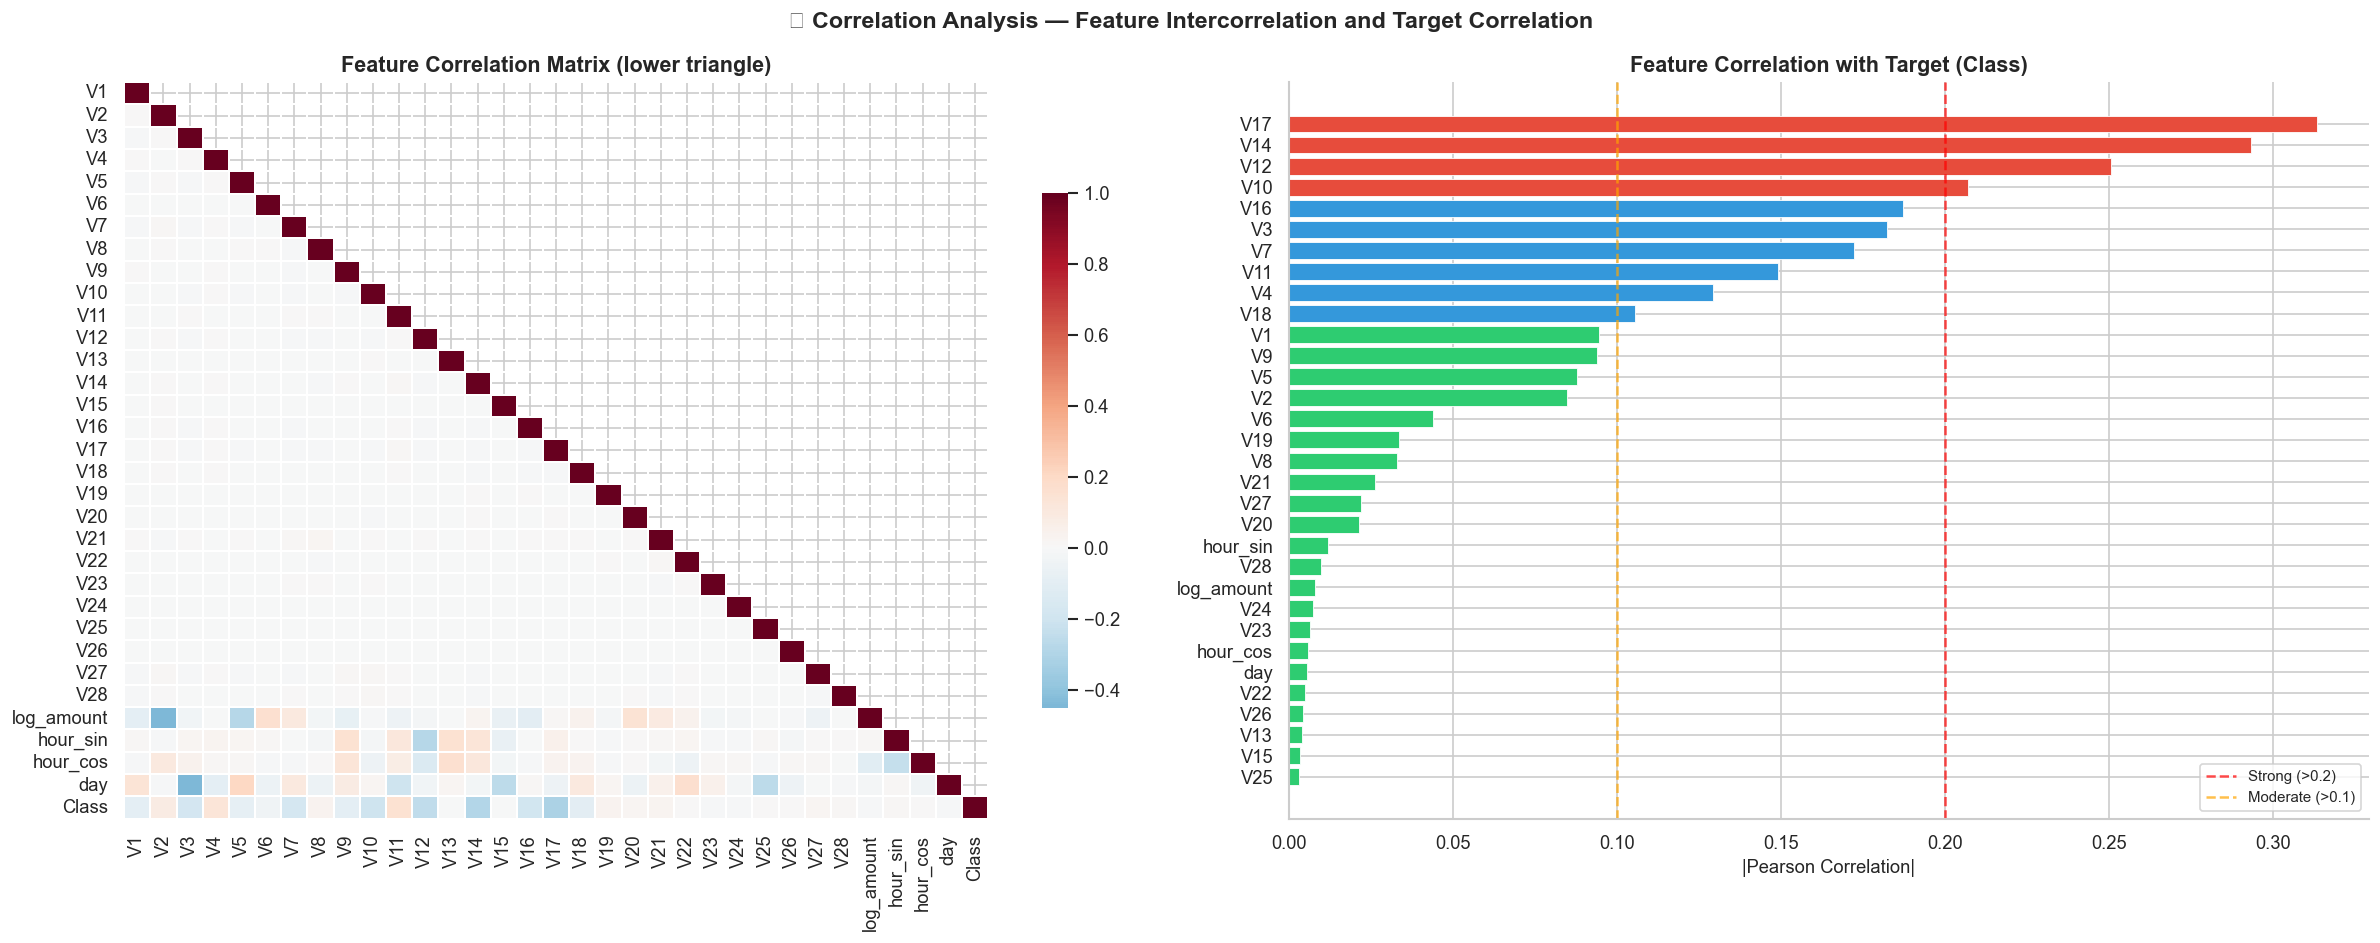

Top 10 features correlated with fraud target:
V17    0.3135
V14    0.2934
V12    0.2507
V10    0.2070
V16    0.1872
V3     0.1823
V7     0.1723
V11    0.1491
V4     0.1293
V18    0.1053


In [17]:
# Ensure engineered features exist in df
if "log_amount" not in df.columns:
    df["log_amount"] = np.log1p(df["Amount"])
if "hour" not in df.columns:
    df["hour"] = (df["Time"] // 3600) % 24
if "hour_sin" not in df.columns:
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
if "hour_cos" not in df.columns:
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
if "day" not in df.columns:
    df["day"] = (df["Time"] // (3600 * 24)).astype(int)

corr_cols   = v_cols + ["log_amount", "hour_sin", "hour_cos", "day", "Class"]
corr_matrix = df[corr_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Full heatmap
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap="RdBu_r",
            center=0, linewidths=0.2, ax=axes[0],
            cbar_kws={"shrink": 0.7})
axes[0].set_title("Feature Correlation Matrix (lower triangle)")

# Target correlations bar chart
target_corr = corr_matrix["Class"].drop("Class").abs().sort_values(ascending=False)
colors_bar  = [FRAUD_COLOR if v > 0.2 else ACCENT_COLOR if v > 0.1 else LEGIT_COLOR
               for v in target_corr]
axes[1].barh(target_corr.index[::-1], target_corr.values[::-1],
             color=colors_bar[::-1], edgecolor="white", linewidth=0.5)
axes[1].axvline(0.2, color="red",    linestyle="--", alpha=0.7, label="Strong (>0.2)")
axes[1].axvline(0.1, color="orange", linestyle="--", alpha=0.7, label="Moderate (>0.1)")
axes[1].set_title("Feature Correlation with Target (Class)")
axes[1].set_xlabel("|Pearson Correlation|")
axes[1].legend(fontsize=9)

plt.suptitle("\U0001f517 Correlation Analysis \u2014 Feature Intercorrelation and Target Correlation",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("Top 10 features correlated with fraud target:")
print(target_corr.head(10).round(4).to_string())

📌 **Observation:**

- Left panel: the 28 PCA features are essentially uncorrelated with each other (pale off-diagonal), as PCA guarantees. The engineered columns are the exception — `log_amount` and `day` show visible correlations with some components (up to roughly |0.4|, e.g. `log_amount` with `V2` and `day` with `V3`).
- Right panel (|Pearson| with `Class`): four features pass the "strong" line (> 0.2) — **V17 (0.313), V14 (0.293), V12 (0.251), V10 (0.207)**; six more fall in the "moderate" band 0.1–0.2 — **V16 (0.187), V3 (0.182), V7 (0.172), V11 (0.149), V4 (0.129), V18 (0.105)**; every other feature, including `log_amount`, `hour_sin`, `hour_cos` and `day`, is below 0.1 (the engineered ones below ~0.01–0.02).
- V17 ranks above V14 here, while V14 ranks first by mean difference in Step 15 — the two measures weigh scale and shape differently.

💡 **Pipeline decision:** No multicollinearity removal is needed among the PCA features. The correlation of `log_amount` and `day` with several components is moderate and does not call for dropping them; `day` is excluded as a model input for a different reason (Step 11). `SelectKBest` handles feature reduction for the linear models, and a VIF check is only needed if non-PCA features are added later.

---
## Step 18 — Outlier Analysis by Class
---
**Why:** Outliers affect fraud and legitimate classes differently. Removing outliers from the fraud class is particularly harmful — those extreme transactions may be the most detectable fraud cases. We clip rather than remove to preserve signal.  

**Business insight:** A $25,000 transaction might be a genuine high-value purchase or an extreme fraud case. Either way, it's a real event — not a data error. Clipping to a reasonable range preserves the signal while preventing it from distorting model coefficients.


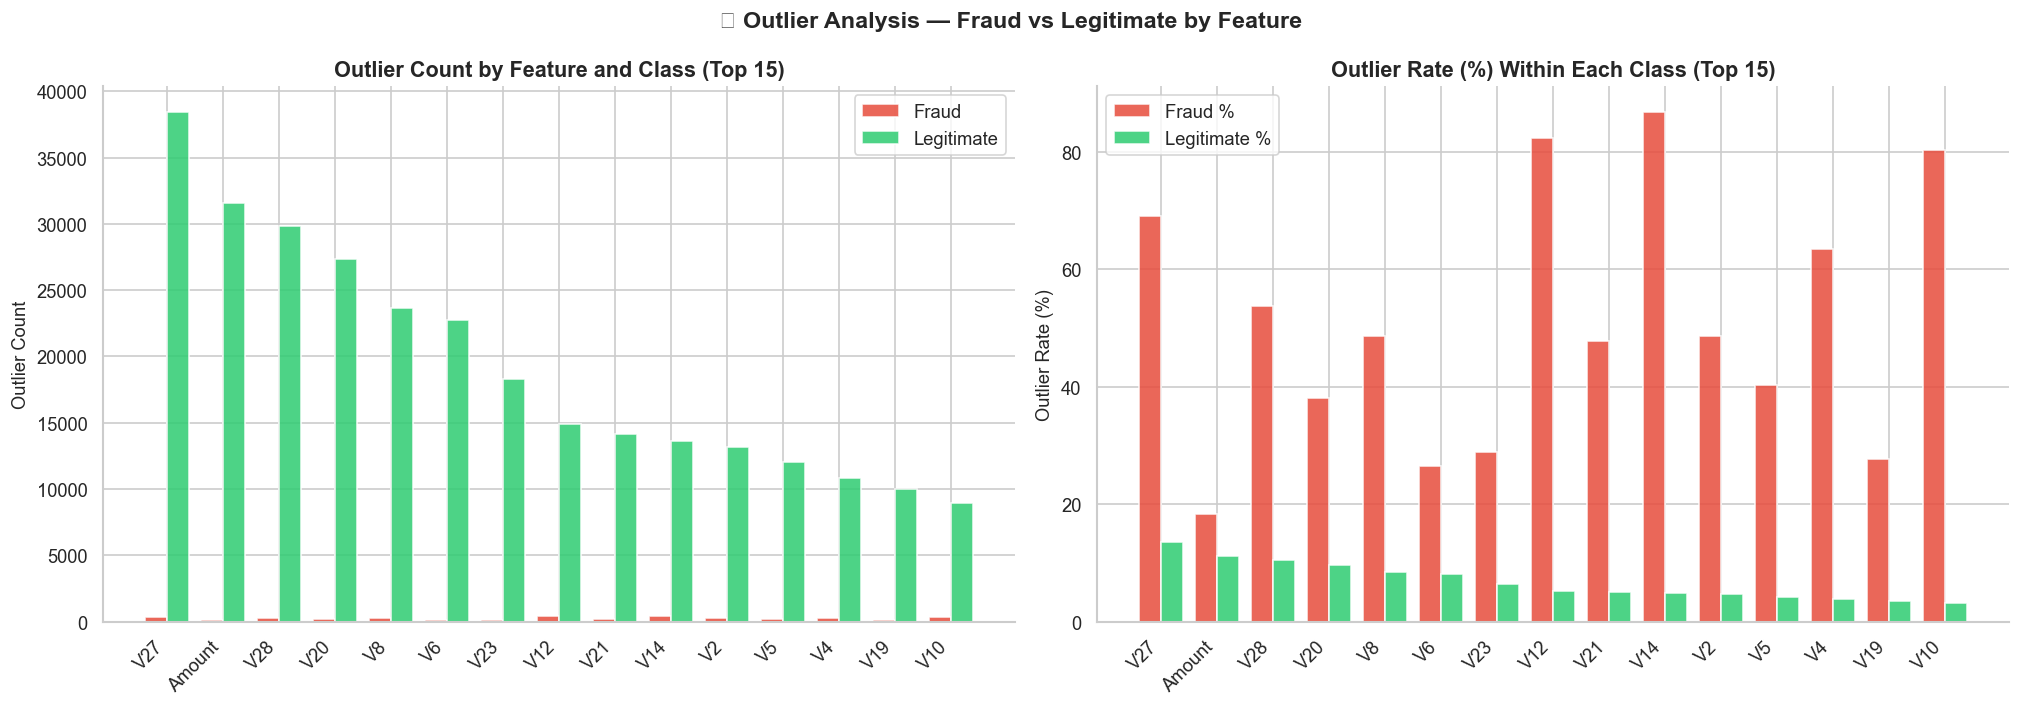

Top 10 features by outlier count:
feature  total_outliers  fraud_outliers  legit_outliers  fraud_pct  legit_pct
    V27           38799             327           38472      69.13      13.58
 Amount           31685              87           31598      18.39      11.16
    V28           30094             254           29840      53.70      10.53
    V20           27553             180           27373      38.05       9.66
     V8           23904             230           23674      48.63       8.36
     V6           22886             125           22761      26.43       8.04
    V23           18467             137           18330      28.96       6.47
    V12           15282             390           14892      82.45       5.26
    V21           14401             226           14175      47.78       5.00
    V14           14060             411           13649      86.89       4.82


In [18]:
outlier_data = []

for col in v_cols + ["Amount"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr   = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    fraud_out = fraud_v[((fraud_v[col] < lower) | (fraud_v[col] > upper))].shape[0]
    legit_out = legit_v[((legit_v[col] < lower) | (legit_v[col] > upper))].shape[0]
    total_out = fraud_out + legit_out

    outlier_data.append({
        "feature":         col,
        "total_outliers":  total_out,
        "fraud_outliers":  fraud_out,
        "legit_outliers":  legit_out,
        "fraud_pct":       round(fraud_out / max(len(fraud_v), 1) * 100, 2),
        "legit_pct":       round(legit_out / max(len(legit_v), 1) * 100, 2),
    })

out_df = pd.DataFrame(outlier_data).sort_values("total_outliers", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

top_out = out_df.head(15)
x = np.arange(len(top_out))
w = 0.4
axes[0].bar(x - w/2, top_out["fraud_outliers"], w, label="Fraud",      color=FRAUD_COLOR, alpha=0.85)
axes[0].bar(x + w/2, top_out["legit_outliers"], w, label="Legitimate", color=LEGIT_COLOR, alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(top_out["feature"], rotation=45, ha="right")
axes[0].set_title("Outlier Count by Feature and Class (Top 15)")
axes[0].set_ylabel("Outlier Count")
axes[0].legend()

axes[1].bar(x - w/2, top_out["fraud_pct"], w, label="Fraud %",      color=FRAUD_COLOR, alpha=0.85)
axes[1].bar(x + w/2, top_out["legit_pct"], w, label="Legitimate %", color=LEGIT_COLOR, alpha=0.85)
axes[1].set_xticks(x)
axes[1].set_xticklabels(top_out["feature"], rotation=45, ha="right")
axes[1].set_title("Outlier Rate (%) Within Each Class (Top 15)")
axes[1].set_ylabel("Outlier Rate (%)")
axes[1].legend()

plt.suptitle("📦 Outlier Analysis — Fraud vs Legitimate by Feature",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("Top 10 features by outlier count:")
print(out_df[["feature","total_outliers","fraud_outliers","legit_outliers",
              "fraud_pct","legit_pct"]].head(10).to_string(index=False))

📌 **Observation:**

- By raw count, `V27` has the most IQR outliers (≈ 38,800), followed by `Amount` (≈ 31,700), `V28`, `V20` and `V8`; the left panel is almost entirely green because 99.8% of rows are legitimate.
- The right panel (outlier **rate** inside each class) is the informative view: **V14 — 86.9% of fraud rows vs 4.8% of legitimate; V12 — 82.5% vs 5.3%; V10 — about 80% vs about 3%**; V27 69.1% vs 13.6%; V4 about 63% vs 4%; V28 53.7% vs 10.5%; `Amount` only 18.4% vs 11.2%.
- Being an outlier in V14, V12 or V10 is therefore itself a strong fraud signal (roughly 15–25× more common among fraud than among legitimate rows).

💡 **Pipeline decision:** IQR-based `Clipper(fold=1.5)` is fitted on training data only and applied to train and test with training statistics — no leakage; values are clipped, never removed. ⚠️ **Review item:** because 80%+ of fraud rows lie beyond the V10 / V12 / V14 fences, clipping at 1.5×IQR collapses most of them onto one boundary value and removes the severity gradient inside the fraud class. Test a wider fold (e.g. 3.0) or skip the Clipper in the tree-model branch.

---
## Step 19 — Fraud Rate by Amount Bucket
---
**Why:** Segmenting transactions into amount bands reveals non-linear risk patterns. The risk is not monotonically increasing with amount — there are hotspot zones that directly inform rule engine thresholds.  

**Business insight:** The $5,000+ threshold in the `rule_engine.py` BLOCK_RULE is justified if this amount bucket shows a significantly elevated fraud rate. This step provides the empirical evidence for that business rule.


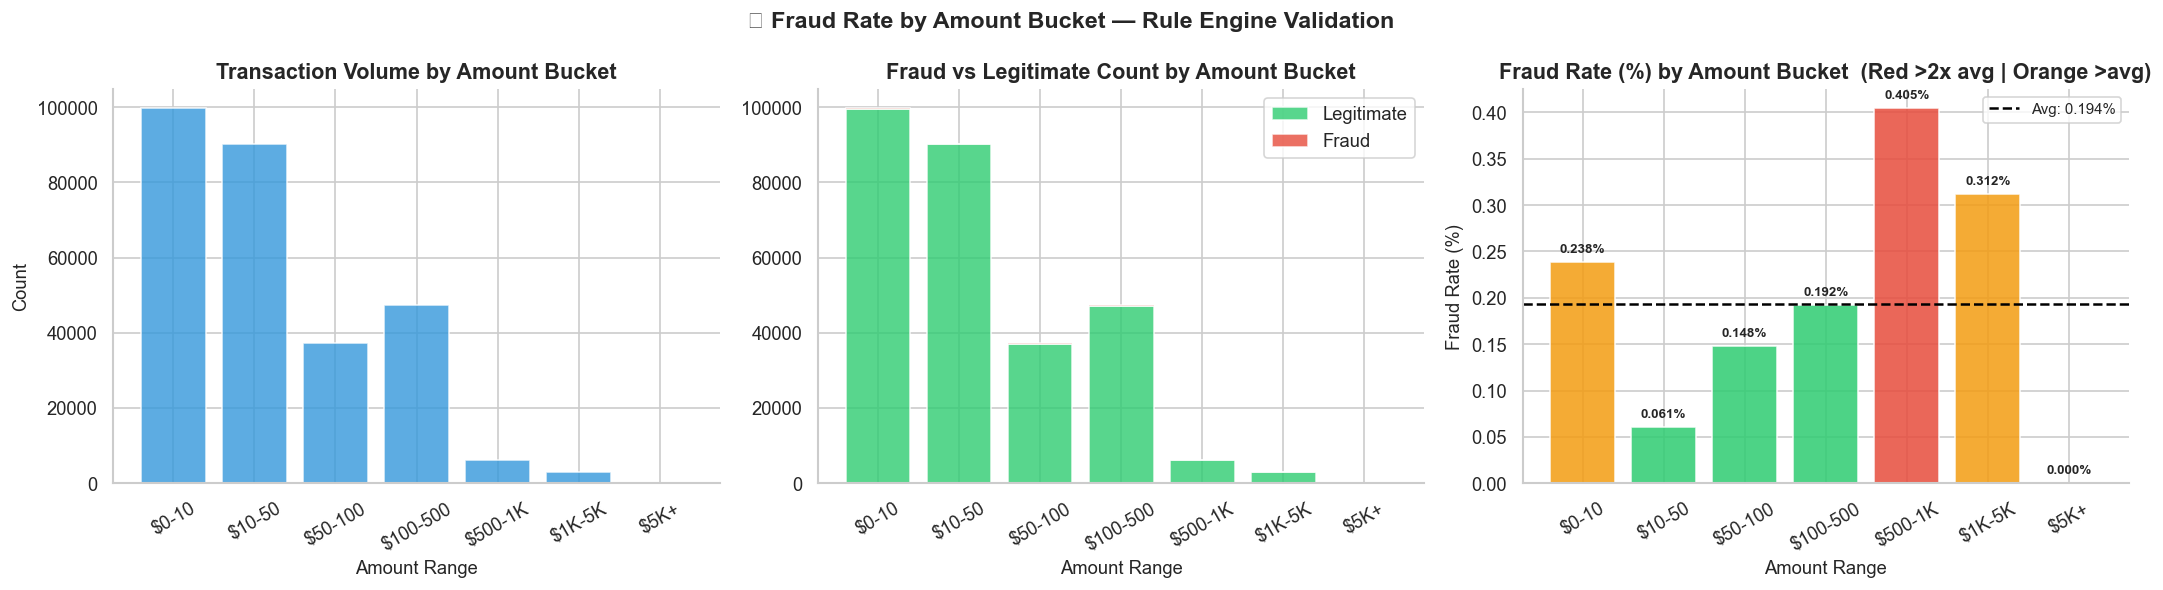

amount_bucket  total  frauds  fraud_rate_pct
        $0-10  99821     238          0.2384
       $10-50  90327      55          0.0609
      $50-100  37179      55          0.1479
     $100-500  47290      91          0.1924
      $500-1K   6174      25          0.4049
       $1K-5K   2880       9          0.3125
         $5K+     55       0          0.0000


In [19]:
bins   = [0, 10, 50, 100, 500, 1000, 5000, float("inf")]
labels = ["$0-10", "$10-50", "$50-100", "$100-500", "$500-1K", "$1K-5K", "$5K+"]

# Ensure Amount_original exists (drop engineered bucket if already exists)
if "amount_bucket" in df.columns:
    df = df.drop(columns=["amount_bucket"])

df["amount_bucket"] = pd.cut(df["Amount"], bins=bins, labels=labels, include_lowest=True)

bucket_stats = df.groupby("amount_bucket", observed=False).agg(
    total      = ("Class", "count"),
    frauds     = ("Class", "sum"),
    fraud_rate = ("Class", "mean"),
).reset_index()
bucket_stats["fraud_rate_pct"] = (bucket_stats["fraud_rate"] * 100).round(4)
bucket_stats["non_fraud"]      = bucket_stats["total"] - bucket_stats["frauds"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Volume
axes[0].bar(bucket_stats["amount_bucket"].astype(str),
            bucket_stats["total"], color=ACCENT_COLOR, alpha=0.8, edgecolor="white")
axes[0].set_title("Transaction Volume by Amount Bucket")
axes[0].set_xlabel("Amount Range")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=30)

# Stacked fraud / legit
axes[1].bar(bucket_stats["amount_bucket"].astype(str),
            bucket_stats["non_fraud"], color=LEGIT_COLOR, alpha=0.8, label="Legitimate")
axes[1].bar(bucket_stats["amount_bucket"].astype(str),
            bucket_stats["frauds"],    color=FRAUD_COLOR, alpha=0.8, label="Fraud",
            bottom=bucket_stats["non_fraud"])
axes[1].set_title("Fraud vs Legitimate Count by Amount Bucket")
axes[1].set_xlabel("Amount Range")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend()

# Fraud rate — colour-coded by severity
avg_rate = bucket_stats["fraud_rate_pct"].mean()
bar_cols = [FRAUD_COLOR if r > avg_rate * 2
            else WARN_COLOR if r > avg_rate
            else LEGIT_COLOR for r in bucket_stats["fraud_rate_pct"]]
axes[2].bar(bucket_stats["amount_bucket"].astype(str),
            bucket_stats["fraud_rate_pct"], color=bar_cols, alpha=0.85, edgecolor="white")
axes[2].axhline(avg_rate, color="black", linestyle="--",
                linewidth=1.5, label=f"Avg: {avg_rate:.3f}%")
axes[2].set_title("Fraud Rate (%) by Amount Bucket  (Red >2x avg | Orange >avg)")
axes[2].set_xlabel("Amount Range")
axes[2].set_ylabel("Fraud Rate (%)")
axes[2].tick_params(axis="x", rotation=30)
axes[2].legend(fontsize=9)
for i, row in bucket_stats.iterrows():
    axes[2].text(i, row["fraud_rate_pct"] + 0.01,
                 f"{row['fraud_rate_pct']:.3f}%", ha="center", fontsize=8, fontweight="bold")

plt.suptitle("\U0001f4a1 Fraud Rate by Amount Bucket \u2014 Rule Engine Validation",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(bucket_stats[["amount_bucket","total","frauds","fraud_rate_pct"]].to_string(index=False))

📌 **Observation:** (overall fraud rate 0.167%)

| Amount bucket | Transactions | Frauds | Fraud rate |
|---|---|---|---|
| $0–10 | 99,821 | 238 | 0.238% |
| $10–50 | 90,327 | 55 | 0.061% |
| $50–100 | 37,179 | 55 | 0.148% |
| $100–500 | 47,290 | 91 | 0.192% |
| $500–1K | 6,174 | 25 | **0.405%** |
| $1K–5K | 2,880 | 9 | 0.313% |
| $5K+ | 55 | **0** | 0.000% |

- Risk is **non-monotonic**: the $500–$5K buckets run at 1.9–2.4× the base rate, and the $0–10 bucket (card testing) holds **238 of the 473 frauds — half of all fraud cases**. The $10–50 range is the safest (0.061%).
- **The $5K+ bucket contains 55 transactions and no fraud at all.** The data therefore does **not** confirm the `Amount > 5000` BLOCK_RULE. With 0 of 55 the result is also inconclusive about safety (the 95% upper bound on the true rate is still ≈ 5%).

💡 **Pipeline decision:** Treat `Amount > 5000 → BLOCK_RULE` as a **business-policy control**, not a data-validated rule — in this sample it would block 55 legitimate transactions and catch no fraud; consider downgrading it to REVIEW. The data supports instead (1) a **REVIEW band for $500–$5K** combined with model probability, and (2) the planned soft rule **`Amount < $10` + high probability → REVIEW** for card-testing patterns.

---
## Step 20 — Feature Engineering Preview
---
**Why:** Documenting every engineered feature with its business rationale and technical implementation ensures traceability between EDA insights and production pipeline code. Each feature here has a corresponding line in `data_loader.py` or `fraud_features.py`.  

**Business insight:** Cyclic sin/cos encoding of `hour` ensures the model understands that 11pm and 1am are two hours apart — not 22 hours apart as linear encoding would imply. This is critical for capturing late-night fraud patterns.


Feature Engineering Preview (6 rows):
 Time  Amount  Class  hour  day  hour_sin  hour_cos  log_amount
  0.0  149.62      0   0.0    0       0.0       1.0      5.0148
  0.0    2.69      0   0.0    0       0.0       1.0      1.3056
  1.0  378.66      0   0.0    0       0.0       1.0      5.9393
  1.0  123.50      0   0.0    0       0.0       1.0      4.8243
  2.0   69.99      0   0.0    0       0.0       1.0      4.2625
  2.0    3.67      0   0.0    0       0.0       1.0      1.5412


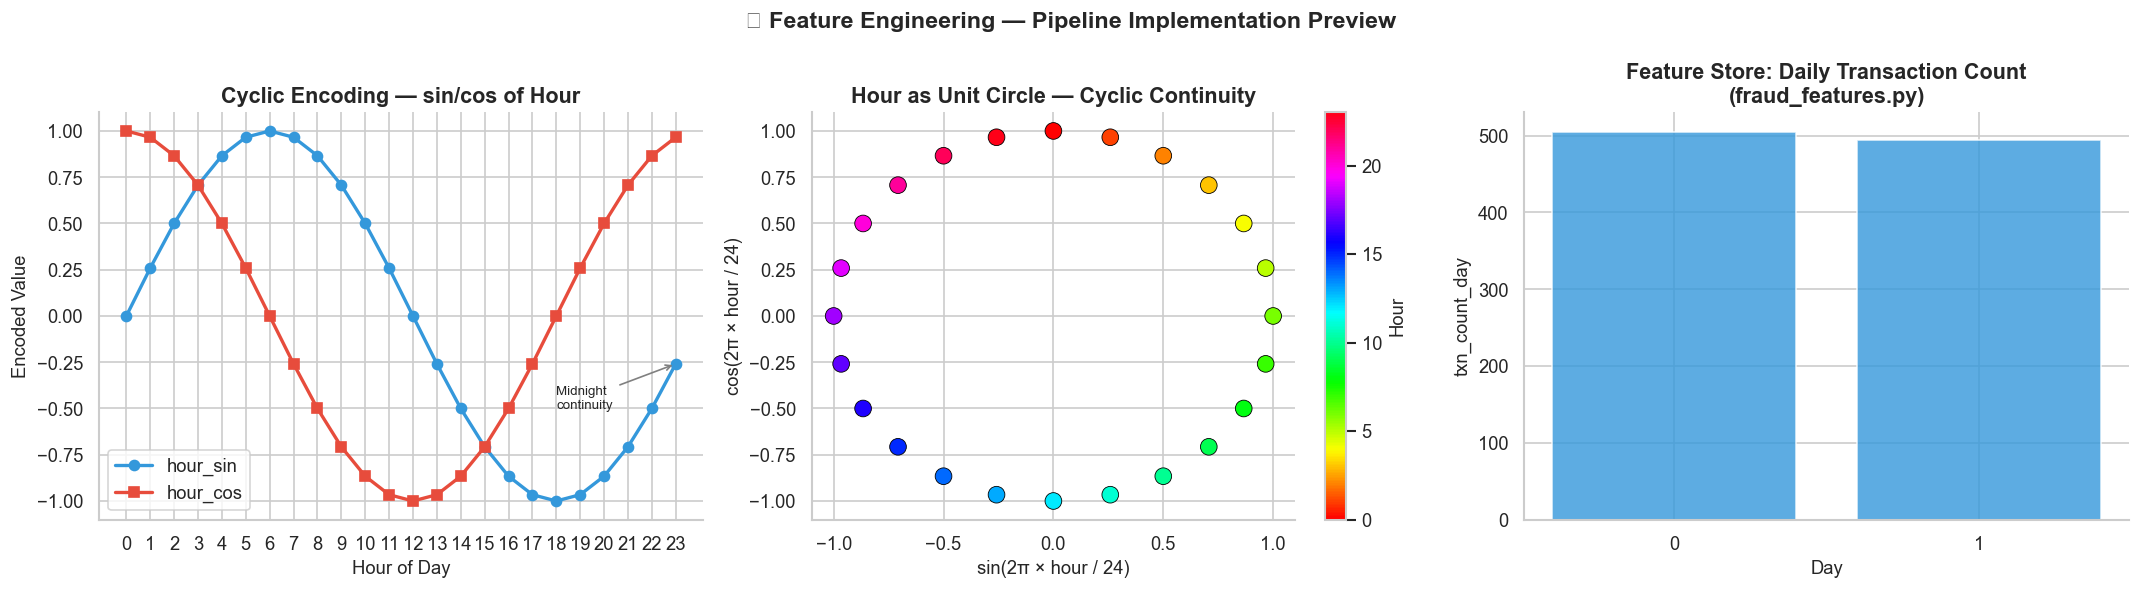


Engineered features and their source modules:
         Feature                   Source                           Business Rationale
            hour           data_loader.py              Night hours = higher fraud rate
             day           data_loader.py                    Day-level velocity signal
        hour_sin           data_loader.py            Cyclic hour — midnight continuity
        hour_cos           data_loader.py            Cyclic hour — midnight continuity
      log_amount           data_loader.py                 Compress right-skewed amount
   txn_count_day        fraud_features.py                   Daily transaction velocity
  avg_amount_day        fraud_features.py                  Baseline amount for the day
amount_deviation        fraud_features.py              Deviation from daily avg amount
graph_risk_score fraud_graph_detection.py  Fraud ring detection via network centrality
   anomaly_score     anomaly_detection.py Statistical anomaly vs training distribut

In [20]:
# ── Preview feature engineering (mirrors production pipeline exactly) ──────
fe_preview = df[["Time", "Amount", "Class"]].head(6).copy()

fe_preview["hour"]         = (fe_preview["Time"] // 3600) % 24
fe_preview["day"]          = (fe_preview["Time"] // 86400).astype(int)
fe_preview["hour_sin"]     = np.sin(2 * np.pi * fe_preview["hour"] / 24)
fe_preview["hour_cos"]     = np.cos(2 * np.pi * fe_preview["hour"] / 24)
fe_preview["log_amount"]   = np.log1p(fe_preview["Amount"])

print("Feature Engineering Preview (6 rows):")
print(fe_preview.round(4).to_string(index=False))

# Cyclic encoding visualization
hours    = np.arange(0, 24)
sin_vals = np.sin(2 * np.pi * hours / 24)
cos_vals = np.cos(2 * np.pi * hours / 24)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(hours, sin_vals, "o-", color=ACCENT_COLOR, linewidth=2, label="hour_sin")
axes[0].plot(hours, cos_vals, "s-", color=FRAUD_COLOR,  linewidth=2, label="hour_cos")
axes[0].set_title("Cyclic Encoding — sin/cos of Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Encoded Value")
axes[0].set_xticks(range(0, 24))
axes[0].legend()
axes[0].annotate("Midnight\ncontinuity", xy=(23, sin_vals[23]), xytext=(18, -0.5),
                 arrowprops=dict(arrowstyle="->", color="gray"), fontsize=8)

axes[1].scatter(sin_vals, cos_vals, c=hours, cmap="hsv", s=100, edgecolors="black", linewidths=0.5)
cbar = plt.colorbar(axes[1].collections[0], ax=axes[1])
cbar.set_label("Hour")
axes[1].set_title("Hour as Unit Circle — Cyclic Continuity")
axes[1].set_xlabel("sin(2π × hour / 24)")
axes[1].set_ylabel("cos(2π × hour / 24)")

# Feature store preview
sample = df.sample(1000, random_state=42).copy()
sample["log_amount"] = np.log1p(sample["Amount"])
sample = sample.sort_values("day")
daily_agg = sample.groupby("day")["Amount"].agg(
    txn_count_day="count",
    avg_amount_day="mean"
).reset_index()
axes[2].bar(daily_agg["day"].astype(str), daily_agg["txn_count_day"],
            color=ACCENT_COLOR, alpha=0.8)
axes[2].set_title("Feature Store: Daily Transaction Count\n(fraud_features.py)")
axes[2].set_xlabel("Day")
axes[2].set_ylabel("txn_count_day")

plt.suptitle("🔧 Feature Engineering — Pipeline Implementation Preview",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("\nEngineered features and their source modules:")
fe_table = {
    "Feature":      ["hour","day","hour_sin","hour_cos","log_amount",
                     "txn_count_day","avg_amount_day","amount_deviation",
                     "graph_risk_score","anomaly_score"],
    "Source":       ["data_loader.py","data_loader.py","data_loader.py","data_loader.py","data_loader.py",
                     "fraud_features.py","fraud_features.py","fraud_features.py",
                     "fraud_graph_detection.py","anomaly_detection.py"],
    "Business Rationale": [
        "Night hours = higher fraud rate",
        "Day-level velocity signal",
        "Cyclic hour — midnight continuity",
        "Cyclic hour — midnight continuity",
        "Compress right-skewed amount",
        "Daily transaction velocity",
        "Baseline amount for the day",
        "Deviation from daily avg amount",
        "Fraud ring detection via network centrality",
        "Statistical anomaly vs training distribution",
    ]
}
print(pd.DataFrame(fe_table).to_string(index=False))

📌 **Observation:**

- **10 features** are engineered: 5 direct from `Time` / `Amount` (`hour`, `day`, `hour_sin`, `hour_cos`, `log_amount`), 3 daily velocity features (`txn_count_day`, `avg_amount_day`, `amount_deviation`), plus `graph_risk_score` and `anomaly_score`.
- Cyclic encoding correctly wraps hour 23 → hour 0, and the unit-circle plot shows all 24 hours evenly spaced.
- The velocity features add context that a single transaction cannot provide — but with only two distinct `day` values they are coarse (see Step 11).

💡 **Pipeline decision:** All feature engineering runs in `load_and_engineer()` and `build_fraud_features()` **before** the preprocessor, ensuring identical transformations for training and inference. Graph and anomaly features need full-batch context and are computed separately; Step 21 shows that `graph_risk_score` currently carries no signal.

---
## Step 21 — Graph Risk Score Analysis
---
**Why:** Fraud is rarely isolated — organised fraud rings use multiple cards targeting the same merchants or amount patterns. Graph-based features capture this network structure that purely tabular features miss entirely.  

**Business insight:** A cardholder who transacts at the same "merchant" (proxied by amount bucket) as many other suspicious cards has an elevated network centrality score — a signal that no per-transaction feature can detect alone.


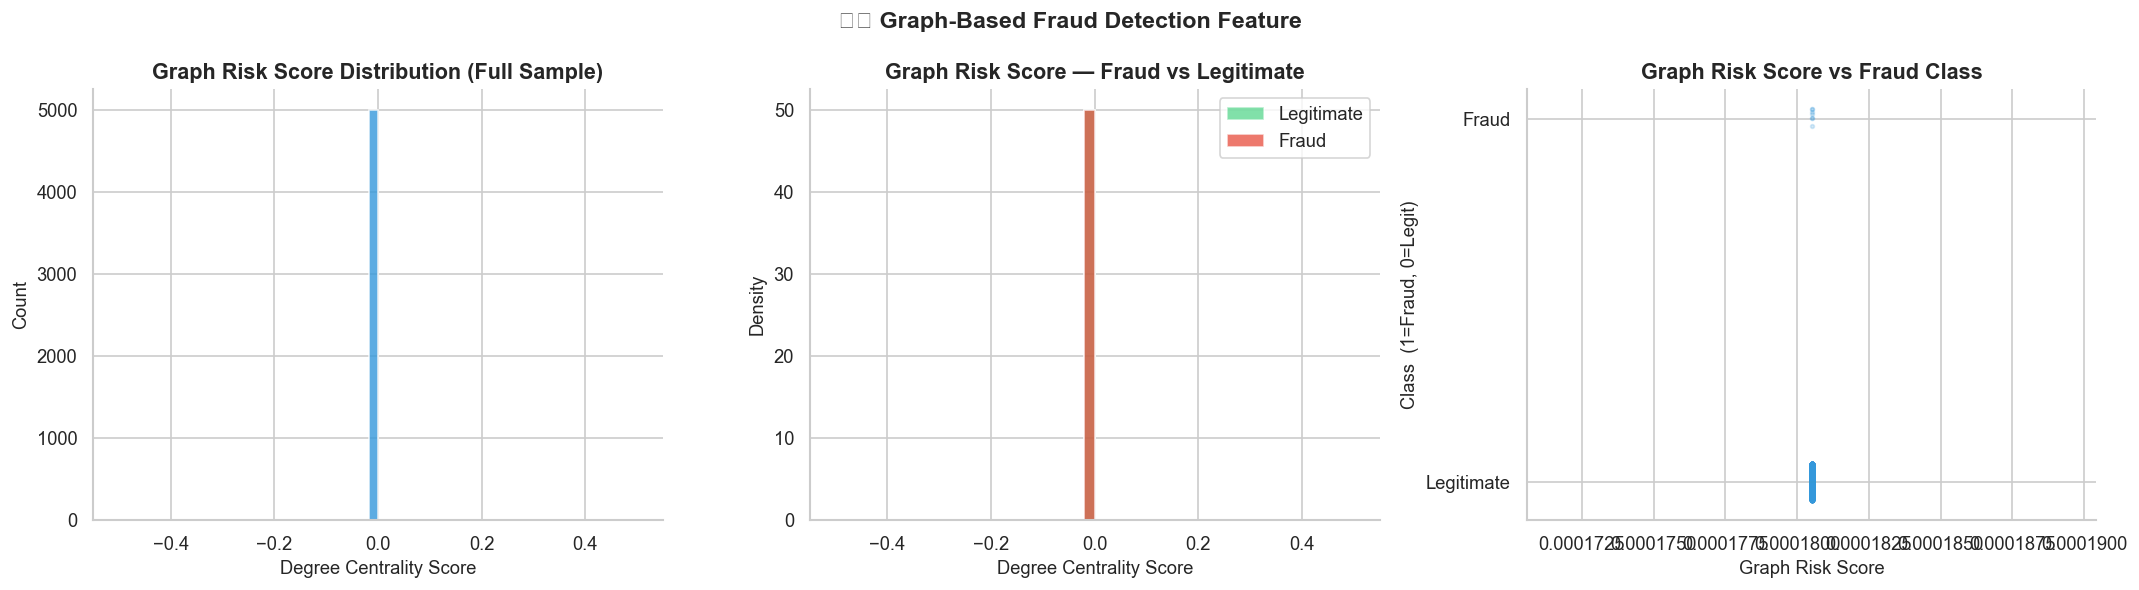

Graph statistics (on 5,000 sample transactions):
  Nodes : 5,541  (card nodes + merchant nodes)
  Edges : 5,000

Graph Risk Score statistics by class:
           mean    median  std       max
Class                                   
0      0.000181  0.000181  0.0  0.000181
1      0.000181  0.000181  0.0  0.000181


In [21]:
# Graph analysis on a representative sample
sample_g = df.sample(n=5000, random_state=42).reset_index(drop=True)
sample_g["log_amount"] = np.log1p(sample_g["Amount"])

# Build transaction graph: card_node ↔ merchant_node (proxied by amount bucket)
G = nx.Graph()
for idx, row in sample_g.iterrows():
    card_node     = f"card_{idx}"
    merchant_node = f"merchant_{int(row['Amount'])}"
    G.add_edge(card_node, merchant_node)

centrality = nx.degree_centrality(G)
sample_g["graph_risk_score"] = [centrality.get(f"card_{i}", 0) for i in range(len(sample_g))]

fraud_g = sample_g[sample_g["Class"] == 1]
legit_g = sample_g[sample_g["Class"] == 0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Full distribution
axes[0].hist(sample_g["graph_risk_score"], bins=60, color=ACCENT_COLOR,
             alpha=0.8, edgecolor="white")
axes[0].set_title("Graph Risk Score Distribution (Full Sample)")
axes[0].set_xlabel("Degree Centrality Score")
axes[0].set_ylabel("Count")

# By class
axes[1].hist(legit_g["graph_risk_score"], bins=50, alpha=0.6, color=LEGIT_COLOR,
             label="Legitimate", density=True)
axes[1].hist(fraud_g["graph_risk_score"], bins=50, alpha=0.75, color=FRAUD_COLOR,
             label="Fraud",      density=True)
axes[1].set_title("Graph Risk Score — Fraud vs Legitimate")
axes[1].set_xlabel("Degree Centrality Score")
axes[1].set_ylabel("Density")
axes[1].legend()

# Correlation with target
axes[2].scatter(sample_g["graph_risk_score"], sample_g["Class"] + np.random.uniform(-0.05, 0.05, len(sample_g)),
                alpha=0.2, s=5, color=ACCENT_COLOR)
axes[2].set_title("Graph Risk Score vs Fraud Class")
axes[2].set_xlabel("Graph Risk Score")
axes[2].set_ylabel("Class  (1=Fraud, 0=Legit)")
axes[2].set_yticks([0, 1])
axes[2].set_yticklabels(["Legitimate", "Fraud"])

plt.suptitle("🕸️ Graph-Based Fraud Detection Feature",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Graph statistics (on {len(sample_g):,} sample transactions):")
print(f"  Nodes : {G.number_of_nodes():,}  (card nodes + merchant nodes)")
print(f"  Edges : {G.number_of_edges():,}")
print()
print(f"Graph Risk Score statistics by class:")
print(sample_g.groupby("Class")["graph_risk_score"]
      .agg(["mean","median","std","max"]).round(6).to_string())

📌 **Observation:**

- The graph has 5,541 nodes and 5,000 edges, and `graph_risk_score` is **identical for every transaction in both classes** (mean = median = max = 0.000181, std = 0.0).
- Reason: the dataset has no card identifier, so every synthetic "card node" connects to exactly one "merchant node" (the integer amount) and every card node has degree 1. Degree centrality therefore equals the constant 1/(N − 1).
- The feature has **no discriminative power**; the histograms and the scatter plot show a single spike.

💡 **Pipeline decision:** ⚠️ **Review item:** `compute_graph_risk()` cannot add signal on this dataset and should be removed from the feature set (or kept as a placeholder that is switched on only when real entity keys such as card ID and merchant ID are available). Any future version must also solve the known deployment gap: the API cannot rebuild the full graph per request, so a pre-computed centrality lookup from the training batch is required.

---
## Step 22 — Anomaly Score Distribution (Isolation Forest)
---
**Why:** Isolation Forest detects statistical outliers that don't match the training distribution. Applied as a pre-processing step, it adds an unsupervised fraud signal on top of the supervised model — useful for detecting novel fraud patterns not seen during training.  

**Business insight:** Supervised models can only detect fraud patterns seen in training data. Isolation Forest catches structurally anomalous transactions regardless of label — making it a valuable second line of defence against new fraud types.


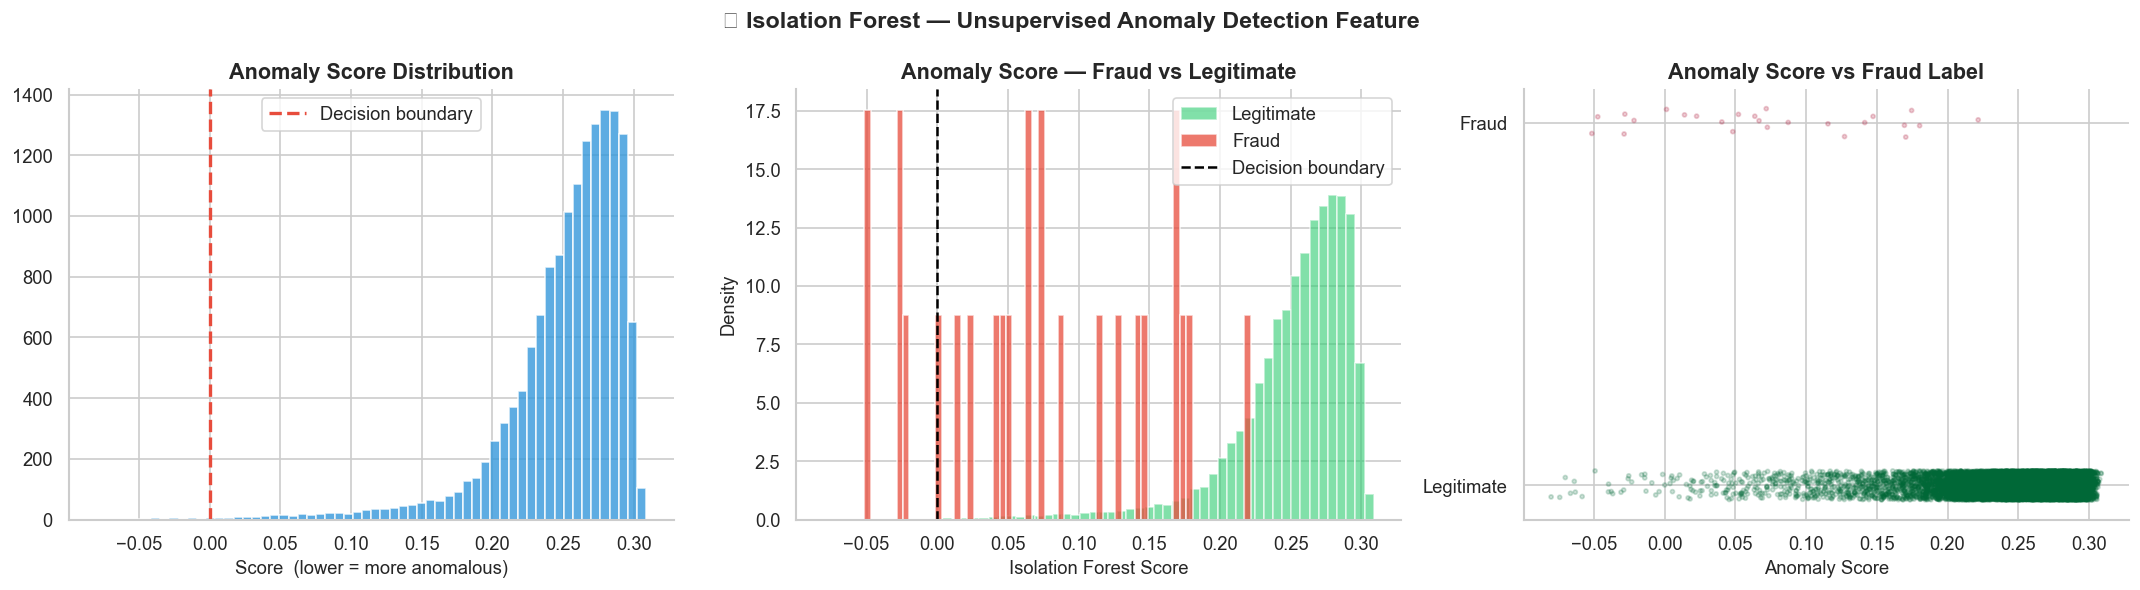

Anomaly Score Statistics by Class:
          mean   median      std      min
Class                                    
0      0.25207  0.26212  0.04295 -0.08042
1      0.07242  0.06669  0.07931 -0.05161

Note: More negative = more isolated = higher anomaly risk
  Fraud mean score   : 0.07242
  Legit mean score   : 0.25207
  Difference         : 0.17965


In [22]:
feature_cols_iso = v_cols + ["log_amount"]
df["log_amount"] = np.log1p(df["Amount"])

# Fit on a sample for speed (production uses full training set)
iso_sample = df.sample(n=15000, random_state=42).copy()

iso = IsolationForest(
    n_estimators  = 100,
    contamination = 0.002,   # ~0.2% fraud rate
    random_state  = 42
)
iso.fit(iso_sample[feature_cols_iso])
iso_sample["anomaly_score"] = iso.decision_function(iso_sample[feature_cols_iso])

fraud_iso = iso_sample[iso_sample["Class"] == 1]
legit_iso = iso_sample[iso_sample["Class"] == 0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribution
axes[0].hist(iso_sample["anomaly_score"], bins=60, color=ACCENT_COLOR,
             alpha=0.8, edgecolor="white")
axes[0].axvline(0, color=FRAUD_COLOR, linestyle="--", linewidth=2, label="Decision boundary")
axes[0].set_title("Anomaly Score Distribution")
axes[0].set_xlabel("Score  (lower = more anomalous)")
axes[0].legend()

# By class
axes[1].hist(legit_iso["anomaly_score"], bins=60, alpha=0.6, color=LEGIT_COLOR,
             label="Legitimate", density=True)
axes[1].hist(fraud_iso["anomaly_score"], bins=60, alpha=0.75, color=FRAUD_COLOR,
             label="Fraud",      density=True)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1.5, label="Decision boundary")
axes[1].set_title("Anomaly Score — Fraud vs Legitimate")
axes[1].set_xlabel("Isolation Forest Score")
axes[1].set_ylabel("Density")
axes[1].legend()

# Anomaly score vs fraud probability (scatter)
axes[2].scatter(iso_sample["anomaly_score"],
                iso_sample["Class"] + np.random.uniform(-0.04, 0.04, len(iso_sample)),
                alpha=0.2, s=6, c=iso_sample["Class"],
                cmap="RdYlGn_r")
axes[2].set_title("Anomaly Score vs Fraud Label")
axes[2].set_xlabel("Anomaly Score")
axes[2].set_yticks([0, 1])
axes[2].set_yticklabels(["Legitimate", "Fraud"])

plt.suptitle("🔍 Isolation Forest — Unsupervised Anomaly Detection Feature",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("Anomaly Score Statistics by Class:")
print(iso_sample.groupby("Class")["anomaly_score"]
      .agg(["mean","median","std","min"]).round(5).to_string())
print()
print(f"Note: More negative = more isolated = higher anomaly risk")
print(f"  Fraud mean score   : {fraud_iso['anomaly_score'].mean():.5f}")
print(f"  Legit mean score   : {legit_iso['anomaly_score'].mean():.5f}")
print(f"  Difference         : {legit_iso['anomaly_score'].mean() - fraud_iso['anomaly_score'].mean():.5f}")

📌 **Observation:**

- Fraud transactions have much lower anomaly scores than legitimate ones: **mean 0.072 vs 0.252** (difference 0.180); medians 0.067 vs 0.262. Scores are positive on average because `decision_function` is positive for inliers — the printed note "more negative = more anomalous" refers to the direction, and fraud simply sits far closer to the decision boundary.
- Distribution plot: legitimate scores form a bell skewed to the right around 0.25–0.30, with almost nothing below the decision boundary (0); the fraud histogram is spread from about −0.05 to 0.22 with isolated bars. The fraud sample behind this chart is only a couple of dozen points, so the individual bars are single transactions.
- The separation is imperfect: the most anomalous score in the sample (−0.080) belongs to a legitimate transaction (fraud minimum −0.052), and some fraud rows score as ordinary inliers (up to ≈ 0.22).

💡 **Pipeline decision:** `anomaly_filter()` in `anomaly_detection.py` fits Isolation Forest on `X_train` and applies `decision_function` to train and test using **training statistics only** to avoid leakage. The `anomaly_score` is added as a feature column alongside the PCA features, giving the supervised model an unsupervised second opinion on novel patterns.

---
## Step 23 — Class Imbalance — SMOTE Preview
---
**Why:** SMOTE (Synthetic Minority Over-sampling Technique) generates synthetic fraud samples in feature space to balance the training distribution. This is applied **only on training data** — test set remains untouched to give honest evaluation metrics.  

**Business insight:** Without SMOTE, models trained on 598:1 imbalanced data learn to almost always predict "legitimate" — a fatal outcome for a fraud detection system. SMOTE forces the model to learn fraud patterns by making them equally represented in training.


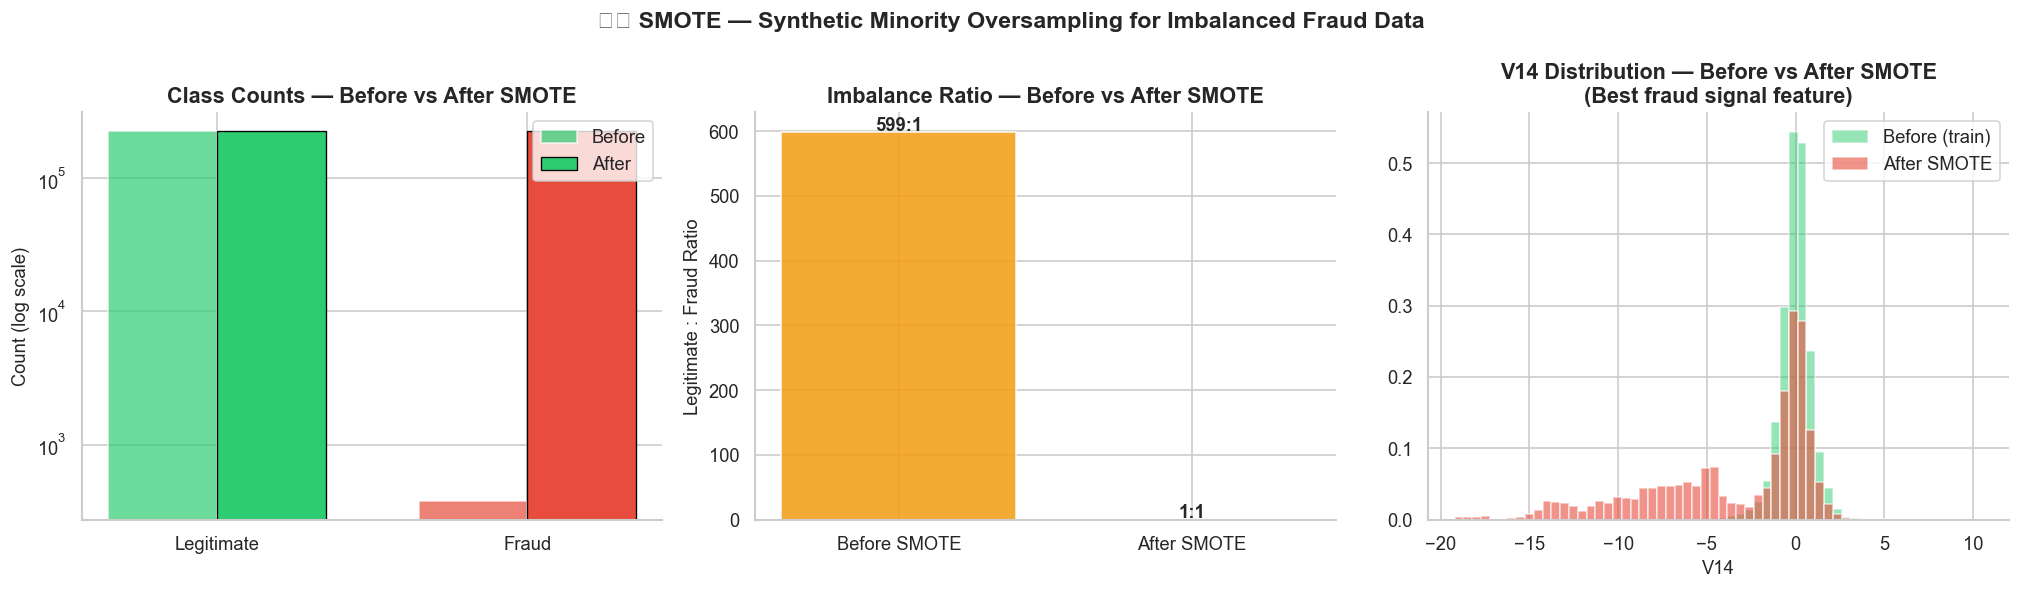

Class distribution comparison:
       Before SMOTE  After SMOTE
Class                           
0            226602       226602
1               378       226602

Training set size before SMOTE: 226,980
Training set size after SMOTE : 453,204
Synthetic fraud samples added : 226,224

⚠️  SMOTE is applied to training set ONLY — test set is untouched
    Test fraud rate remains: 0.1674 %


In [23]:
feature_cols_smote = v_cols + ["log_amount", "hour_sin", "hour_cos", "day"]
df["log_amount"] = np.log1p(df["Amount"])
df["hour"]       = (df["Time"] // 3600) % 24
df["hour_sin"]   = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"]   = np.cos(2 * np.pi * df["hour"] / 24)
df["day"]        = (df["Time"] // 86400).astype(int)

X = df[feature_cols_smote]
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

before_counts = pd.Series(y_train).value_counts().rename("Before SMOTE")
after_counts  = pd.Series(y_train_res).value_counts().rename("After SMOTE")
comparison    = pd.concat([before_counts, after_counts], axis=1)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Before / After bar
x  = np.arange(2)
w  = 0.35
b0, b1 = before_counts[0], before_counts[1]
a0, a1 = after_counts[0],  after_counts[1]
axes[0].bar(x - w/2, [b0, b1], w, color=[LEGIT_COLOR, FRAUD_COLOR], alpha=0.7, label="Before")
axes[0].bar(x + w/2, [a0, a1], w, color=[LEGIT_COLOR, FRAUD_COLOR], alpha=1.0, label="After",
            edgecolor="black", linewidth=0.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Legitimate", "Fraud"])
axes[0].set_yscale("log")
axes[0].set_title("Class Counts — Before vs After SMOTE")
axes[0].set_ylabel("Count (log scale)")
axes[0].legend()

# Ratio comparison
axes[1].bar(["Before SMOTE", "After SMOTE"],
            [b0 / b1, a0 / a1], color=[WARN_COLOR, LEGIT_COLOR], alpha=0.85, edgecolor="white")
axes[1].set_title("Imbalance Ratio — Before vs After SMOTE")
axes[1].set_ylabel("Legitimate : Fraud Ratio")
for i, v in enumerate([b0/b1, a0/a1]):
    axes[1].text(i, v + 2, f"{v:.0f}:1", ha="center", fontweight="bold", fontsize=11)

# V14 distribution before vs after SMOTE
axes[2].hist(X_train["V14"],     bins=60, alpha=0.5, color=LEGIT_COLOR,
             label="Before (train)", density=True)
axes[2].hist(X_train_res["V14"], bins=60, alpha=0.6, color=FRAUD_COLOR,
             label="After SMOTE",   density=True)
axes[2].set_title("V14 Distribution — Before vs After SMOTE\n(Best fraud signal feature)")
axes[2].set_xlabel("V14")
axes[2].legend()

plt.suptitle("⚖️ SMOTE — Synthetic Minority Oversampling for Imbalanced Fraud Data",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("Class distribution comparison:")
print(comparison.to_string())
print()
print(f"Training set size before SMOTE: {len(X_train):,}")
print(f"Training set size after SMOTE : {len(X_train_res):,}")
print(f"Synthetic fraud samples added : {a1 - b1:,}")
print()
print("⚠️  SMOTE is applied to training set ONLY — test set is untouched")
print("    Test fraud rate remains:", round(y_test.mean() * 100, 4), "%")

📌 **Observation:**

- The 80% training split holds **226,602 legitimate vs 378 fraud (599 : 1)**. SMOTE generates **226,224 synthetic fraud rows**, giving 226,602 : 226,602 and a training set of 453,204 rows.
- The test set is untouched; its fraud rate stays at **0.1674%**, so evaluation remains honest.
- Note the scale of the expansion: roughly **600 synthetic points per real fraud case**.

💡 **Pipeline decision:** `SMOTE(random_state=42)` runs inside `tune_models()` as part of the `ImbPipeline`, so it is fitted on training folds only and never on validation folds. Because so few real fraud cases seed the synthetic data, a partial target ratio (e.g. `sampling_strategy=0.1`) and `scale_pos_weight` are worth benchmarking against full 1 : 1 balancing.

---
## Step 24 — Feature Scaling Preview
---
**Why:** Distance-based models (Logistic Regression, KNN, SGD) require features on the same scale — otherwise, a feature with range [0, 25000] dominates over features in range [−5, 5]. Tree-based models (ExtraTrees, XGBoost, LightGBM) are scale-invariant.  

**Business insight:** Using a single preprocessor for all models is a common mistake. A tree model trained on scaled features performs identically — but a linear model trained on unscaled features performs poorly. The dual-preprocessor architecture matches each model to its optimal input format.


Features requiring PowerTransform (skewness > 1.0) : 14
Features requiring only StandardScaler             : 18


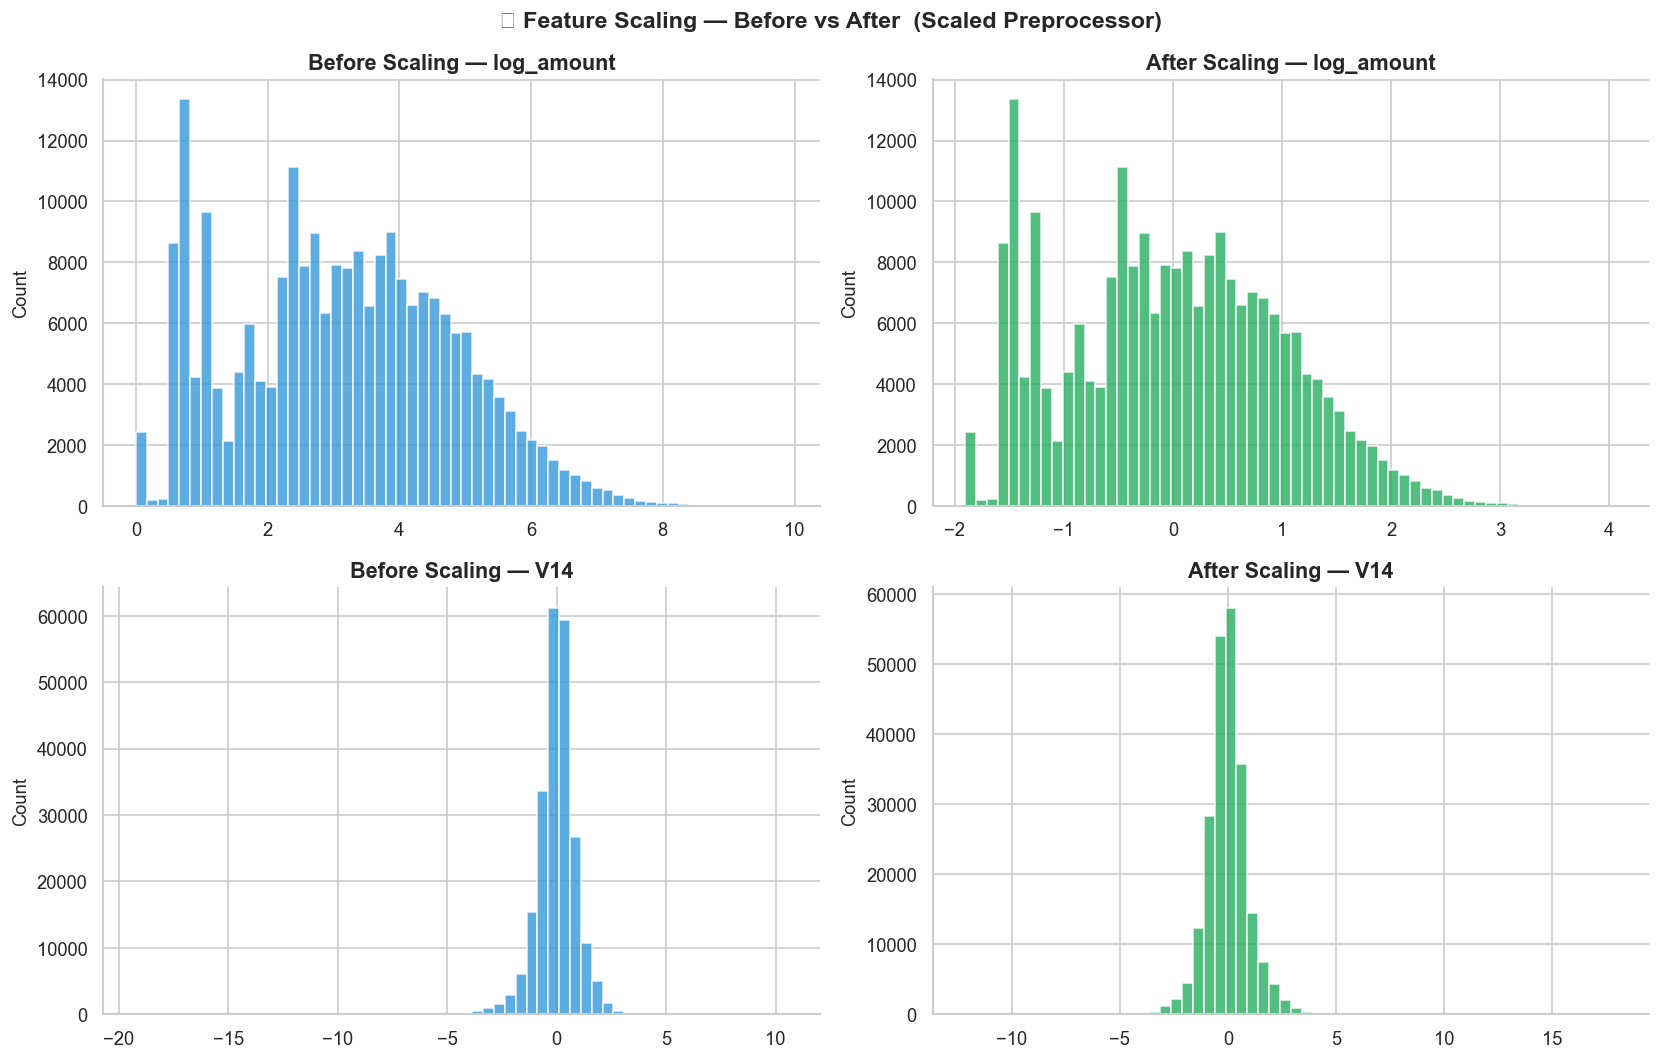


Dual-Preprocessor Architecture:
┌─────────────────────────────────────────────────────────────────┐
│  pre_scaled   → Clipper → PowerTransformer → StandardScaler     │
│                → LogisticRegression, SGD, KNN, GaussianNB       │
├─────────────────────────────────────────────────────────────────┤
│  pre_unscaled → passthrough (raw columns)                       │
│                → ExtraTrees, XGBoost, LightGBM, CatBoost        │
└─────────────────────────────────────────────────────────────────┘


In [24]:
from sklearn.preprocessing import PowerTransformer

sample_s = X_train.copy()

skewed_cols = [c for c in sample_s.columns if abs(sample_s[c].skew()) > 1.0]
normal_cols = [c for c in sample_s.columns if c not in skewed_cols]

print(f"Features requiring PowerTransform (skewness > 1.0) : {len(skewed_cols)}")
print(f"Features requiring only StandardScaler             : {len(normal_cols)}")

# Apply transforms
scaler  = StandardScaler()
pt      = PowerTransformer(method="yeo-johnson", standardize=False)

sample_scaled = sample_s.copy()
if skewed_cols:
    sample_scaled[skewed_cols] = pt.fit_transform(sample_s[skewed_cols])
if len(sample_scaled.columns) > 0:
    sample_scaled[sample_scaled.columns] = scaler.fit_transform(sample_scaled)

# Show transformation effect for 2 key features
show_features = ["log_amount", "V14"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, feat in enumerate(show_features):
    if feat not in sample_s.columns:
        continue
    axes[i, 0].hist(sample_s[feat],     bins=60, color=ACCENT_COLOR,
                    alpha=0.8, edgecolor="white")
    axes[i, 0].set_title(f"Before Scaling — {feat}")
    axes[i, 0].set_ylabel("Count")

    axes[i, 1].hist(sample_scaled[feat], bins=60, color="#27AE60",
                    alpha=0.8, edgecolor="white")
    axes[i, 1].set_title(f"After Scaling — {feat}")
    axes[i, 1].set_ylabel("Count")

plt.suptitle("📐 Feature Scaling — Before vs After  (Scaled Preprocessor)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("\nDual-Preprocessor Architecture:")
print("┌─────────────────────────────────────────────────────────────────┐")
print("│  pre_scaled   → Clipper → PowerTransformer → StandardScaler     │")
print("│                → LogisticRegression, SGD, KNN, GaussianNB       │")
print("├─────────────────────────────────────────────────────────────────┤")
print("│  pre_unscaled → passthrough (raw columns)                       │")
print("│                → ExtraTrees, XGBoost, LightGBM, CatBoost        │")
print("└─────────────────────────────────────────────────────────────────┘")

📌 **Observation:**

- Of the 32 model features (28 PCA components + `log_amount`, `hour_sin`, `hour_cos`, `day`), **14 are skewed (|skew| > 1)** and need the Yeo-Johnson PowerTransformer; the other **18** only need standardisation.
- The PCA components are zero-mean but have unequal variances and heavy tails, so they also benefit from scaling; the before/after plots show the transformed features centred and compact.

💡 **Pipeline decision:** `build_preprocessors()` in `preprocessing.py` returns two `ColumnTransformer` objects — `pre_scaled` for linear and distance-based models, and `pre_unscaled` (passthrough) for tree models. Each model grid in `model_tuning.py` is matched to its correct preprocessor during tuning.

---
## Step 25 — Key Insights Summary
---
**Why:** An EDA only creates value when each finding is traceable to a pipeline decision. This closing step consolidates the headline statistics and the full finding-to-decision map in one place.  

**Business insight:** For a fraud system, a written decision map is the audit trail for model-risk and compliance teams — it shows which business rules are data-backed (and which are policy-driven) and which open items still need a decision.

In [25]:
print("=" * 70)
print("  CREDIT CARD FRAUD DETECTION — EDA COMPLETE")
print("=" * 70)
print(f"  Dataset rows         : {df.shape[0]:>12,}")
print(f"  Features             : {df.shape[1]:>12,}")
print(f"  Fraud rate           : {df['Class'].mean()*100:>11.4f}%")
print(f"  Imbalance ratio      : {(df['Class']==0).sum() // (df['Class']==1).sum():>10,}:1")
print(f"  Top fraud feature    : {'V14':>12}")
print(f"  Primary metric       : {'PR-AUC':>12}")
print(f"  Imbalance fix        : {'SMOTE':>12}")
print(f"  Amount transform     : {'log1p':>12}")
print(f"  Engineered features  : {'10':>12}")
print("=" * 70)

  CREDIT CARD FRAUD DETECTION — EDA COMPLETE
  Dataset rows         :      283,726
  Features             :           37
  Fraud rate           :      0.1667%
  Imbalance ratio      :        598:1
  Top fraud feature    :          V14
  Primary metric       :       PR-AUC
  Imbalance fix        :        SMOTE
  Amount transform     :        log1p
  Engineered features  :           10


📌 **Observation:**

- Final cleaned dataset: **283,726 transactions, 0.167% fraud (598 : 1)**; top signal features V14, V3, V17, V12, V10; fraud concentrates at **02:00–04:00** and in micro-amounts (**$0–10 holds ~50% of all fraud cases**) as well as in the $500–$5K range.
- Three claims in the original pipeline design are **not confirmed by the data** and are marked ⚠️ in the map below: the `Amount > 5000` BLOCK_RULE, `graph_risk_score` (constant on this dataset) and 1.5×IQR clipping of the V12 / V14 outliers.

💡 **Pipeline decision:** Carry the decision map below into the model-risk documentation. Before the next training run resolve the three ⚠️ items (downgrade or justify the $5K rule, remove or redesign `graph_risk_score`, test a wider Clipper fold), then proceed to model tuning.

### 📋 EDA-to-Pipeline Decision Map

| # | EDA Finding | Pipeline Decision |
|---|-------------|-------------------|
| 1 | **0.167% fraud rate (598 : 1 imbalance, 473 frauds after dedup)** | SMOTE (training folds only) + `scale_pos_weight`; PR-AUC / F1 as primary metrics — not accuracy |
| 2 | **1,081 duplicate rows (19 fraud) removed** | `drop_duplicates()` inside `validate_input_data()` before the split |
| 3 | **Amount is right-skewed (skew 16.98 → 0.16 after log1p)** | `log1p(Amount)` in `load_and_engineer()`; `Amount_original` kept for cost evaluation |
| 4 | **Fraud peaks at 02:00–04:00 (1.45% at 02:00, ≈ 8.7× overall)** | `hour_sin`, `hour_cos` features; optional `is_night_risk` flag for tree models |
| 5 | **V14, V3, V17, V12, V10 = top fraud signals; 7 PCA features below 0.1 separation** | `SelectKBest(k=20)` retains the strong features and drops the weakest 8 |
| 6 | **$500– $5K buckets at 1.9–2.4× base rate; $5K+ has 55 txns and 0 fraud** | ⚠️ `Amount > 5000 → BLOCK_RULE` is not data-validated — treat as policy or downgrade to REVIEW; add a REVIEW band for $500–$5K |
| 7 | **$0–10 bucket holds half of all fraud (card testing)** | Soft rule: `Amount < $10` + high probability → REVIEW |
| 8 | **PCA features are already orthogonal** | No multicollinearity removal needed; VIF check skipped |
| 9 | **82–87% of fraud rows are IQR outliers in V12 / V14** | ⚠️ `Clipper(fold=1.5)` clips (does not remove), but test fold = 3.0 or no clipping for tree models |
| 10 | **`graph_risk_score` is constant (0.000181) — no card ID in the data** | ⚠️ Remove from this feature set or redesign when real entity keys exist |
| 11 | **Isolation Forest: fraud mean 0.072 vs legit 0.252** | `anomaly_score` added as a pipeline feature (fit on training data only) |
| 12 | **`day` has only two values (fraud 0.19% vs 0.14%)** | Use `day` only for daily aggregates and PSI baseline — not as a raw model feature |
| 13 | **Dual preprocessor required (14 skewed, 18 normal-scale features)** | `pre_scaled` → linear models; `pre_unscaled` → tree models |

---

### 🏗️ Pipeline Flow (EDA → Production)

```
Raw CSV (creditcard.csv)
   │
   ▼  validate_input_data()          → column checks, null check, dedup, target validation
   ▼  load_and_engineer()            → hour, day, hour_sin, hour_cos, log_amount, Amount_original
   ▼  build_fraud_features()         → txn_count_day, avg_amount_day, amount_deviation
   ▼  compute_graph_risk()           → graph_risk_score  (networkx degree centrality)
   ▼  anomaly_filter()               → anomaly_score     (IsolationForest decision_function)
   ▼  fast_training_sample()         → balanced screening sample (20:1 ratio)
   ▼  build_preprocessors()          → pre_scaled (Clipper→Power→StandardScaler)
   │                                 → pre_unscaled (Clipper→passthrough)
   ▼  tune_models()                  → 11 models × RandomizedSearchCV × PR-AUC
   ▼  evaluate_models()              → PR-AUC ranking, threshold tuning, cost evaluation
   ▼  rule_engine()                  → BLOCK_RULE | BLOCK_MODEL | REVIEW | APPROVE
   ▼  Save + Registry                → fraud_model_v1.joblib + latest_model.json
   ▼  FastAPI /predict               → real-time inference with feature engineering
   ▼  Streamlit dashboard            → monitoring, drift alerts, decision distribution
```

---

*EDA completed by Narendra Kalam — Credit Card Fraud Detection ML System*
